# NLP Numericals Solved by Hand: From Bag of Words to Transformers, BLEU and BPE

> **Who is this for:** students preparing for NLP exams, quizzes and interviews who want to *calculate* NLP quantities with pen and paper. It fits a university NLP course and the topics of the popular sequence-models and NLP specialization courses (we use their outlines only as a checklist; every problem and number here is original).
>
> **What you will learn:**
> - classic text counts: tokens, vocabulary, bag of words, TF-IDF (two IDF formulas) and cosine similarity
> - two sentiment classifiers by hand: word-frequency features with logistic regression, and Naive Bayes with Laplace smoothing
> - word vectors: Euclidean vs cosine, analogies, bias neutralization, word translation with a matrix $R$, locality-sensitive hashing
> - edit distance, autocorrect, n-gram language models (add-one, add-k, backoff, interpolation, perplexity) and HMM tagging with Viterbi
> - word2vec (skip-gram pairs, softmax, negative sampling, CBOW), the GloVe weighting function, RNN/GRU/LSTM shapes and parameter counts
> - language-model loss and sampling, Siamese networks with triplet loss, beam search with length normalization
> - evaluation: BLEU, ROUGE-1/2/L, word error rate, token-level vs entity-level NER scores
> - attention and Transformers: context vectors, positional encoding, scaled dot-product attention, causal masks, multi-head shapes, BERT masking, BPE merges
>
> **Prerequisites:** [Text to numbers](00_start_here_text_to_numbers.ipynb) (tokens, bag of words and TF-IDF in code) and [ML numericals](../03_Machine_Learning/00c_ml_numericals_solved_by_hand.ipynb) (the same step-by-step style for core machine-learning formulas). School maths: logarithms, exponentials, square roots and dot products.
>
> **Time needed:** about 4-5 hours to work through every problem with pen and paper (the notebook itself runs in a few seconds).
>
> **Runs on:** CPU, no API key, no internet. It needs only numpy, matplotlib and scikit-learn. A few optional cross-checks use nltk, torch, jiwer, seqeval or rouge-score; if one is not installed, the cell prints "skipped" and carries on.

## Explained simply

A **numerical** is a small exam problem: you are given a few numbers (a tiny corpus, a few vectors, a probability table) and you must compute an answer step by step. Real NLP systems do exactly the same arithmetic, only with millions of words.

**Everyday analogy:** it is like learning long division before you use a calculator. Once you have computed TF-IDF for three tiny documents, or run Viterbi on a three-word sentence, the output of a library is no longer magic: you know what it did and you can spot when it is wrong.

**How every section works**

| Part | What you get |
|---|---|
| **Problem** | the given values, usually in a small table |
| **Solution by hand** | numbered steps, the formula in maths notation, every arithmetic step written out |
| **Check with code** | a short pure Python/numpy cell that recomputes everything and uses `assert` to prove the hand answer is right |
| **Try it yourself** | a practice problem; click **Answer** to reveal the worked answer |
| **Common mistake / Exam tip** | the trap that costs most marks |

**Rounding rule (important).** Answers are rounded to 4 decimal places; tiny numbers below 0.01 get 4 significant figures instead (for example 0.002273). Every step uses the *unrounded* result of the step before, exactly as if you kept it in your calculator's memory. So if you round at every step, or add up the rounded numbers shown, your last digit can be off by 1. That is normal and is accepted in exams. Numbers that are exact (like 0.15625 = 5/32) are shown exactly.

**Notation.** $\ln$ is the natural logarithm (base $e$); $\log_2$ is used only for bits. $\sigma(z) = \dfrac{1}{1+e^{-z}}$ is the sigmoid. $\text{softmax}(z)_i = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$. Cosine similarity is $\cos(\mathbf a,\mathbf b)=\dfrac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\,\lVert\mathbf b\rVert}$.

## Contents

0. Setup
1. Tokenization, vocabulary and bag of words
2. TF-IDF (two IDF formulas) and cosine similarity
3. Sentiment with word-frequency features and logistic regression
4. Naive Bayes sentiment with Laplace smoothing
5. Word vectors: Euclidean vs cosine, analogies, bias neutralization
6. Word translation with a matrix $R$, kNN, and locality-sensitive hashing
7. Minimum edit distance (Levenshtein)
8. Autocorrect: candidate words and their probabilities
9. N-gram language models: MLE, add-one, add-k, backoff, interpolation, perplexity
10. HMM part-of-speech tagging and the Viterbi algorithm
11. word2vec: skip-gram pairs, softmax, negative sampling, CBOW
12. GloVe: the weighting function $f(X_{ij})$
13. RNN shapes and RNN vs GRU vs LSTM parameter counts
14. Language-model loss, perplexity, sampling and temperature
15. Siamese networks: cosine similarity and triplet loss
16. Beam search and length normalization
17. BLEU and ROUGE
18. Word error rate (WER)
19. Attention for translation: scores, weights, context vector
20. Transformer numbers: positional encoding, scaled dot-product attention, causal mask, multi-head shapes
21. BERT masked language modelling: the 15% and 80/10/10 rule
22. Byte-pair encoding (BPE) merges
23. NER evaluation: token-level vs entity-level scores

Then: Recap cheat sheet, Related notebooks, Additional learning resources.

## 0. Setup

We import three libraries and define four tiny helpers. The most important one is `check(name, value, hand)`: it compares the value computed by code with the hand answer **written exactly as in the text** (as a string such as `"0.4390"`). It passes only if the code value, rounded to that many decimals, really is the hand answer. If a single hand-worked number were wrong, the notebook would stop with an `AssertionError`.

In [1]:
import math                                    # log, exp, sqrt: the same functions you use by hand
from collections import Counter                # counting words, pairs and n-grams
import numpy as np                             # vectors and matrices
import matplotlib.pyplot as plt                # two small figures

np.set_printoptions(precision=4, suppress=True)   # print arrays with 4 decimals, like the hand work


def check(name, value, hand):
    # Assert that a computed value matches the hand-worked answer.
    # hand as a string ("0.4390"): the code value must round to it (tolerance = half of the last digit).
    # hand as an int: the code value must be exactly equal.
    value = float(value)
    if isinstance(hand, str):
        decimals = len(hand.split(".")[1]) if "." in hand else 0
        ok = abs(value - float(hand)) <= 0.5 * 10 ** (-decimals) + 1e-9
    else:
        ok = abs(value - hand) <= 1e-9
    assert ok, f"{name}: code gives {value:.6f}, hand answer is {hand}"
    print(f"OK  {name:<44} code = {value:<12.6f} hand = {hand}")


def sigmoid(z):
    return 1 / (1 + math.exp(-z))


def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())                    # subtracting the max does not change the result, avoids overflow
    return e / e.sum()


def cosine(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


print("numpy", np.__version__, "| helpers ready")

numpy 2.1.3 | helpers ready


## 1. Tokenization, vocabulary and bag of words

**What it is.** *Tokenization* chops text into pieces called **tokens** (here: words). The **vocabulary** $V$ is the list of *distinct* tokens (also called *types*). A **bag-of-words (BoW)** vector counts how often each vocabulary word appears in a sentence and ignores word order.

**Everyday analogy.** Tip the sentence into a bag of word tiles, shake it, and count the tiles of each kind. The order is lost; the counts remain.

**How it works.** Lowercase, split on spaces, list the distinct words in alphabetical order, then count.

### Problem

| id | sentence |
|---|---|
| S1 | I like green tea |
| S2 | I like tea and I like coffee |
| S3 | green tea is green |

Rules: lowercase everything and split on spaces (there is no punctuation). Find:

(a) the number of tokens in each sentence and in total; (b) the vocabulary and its size $|V|$; (c) the BoW count vector of each sentence (columns in alphabetical order); (d) the BoW vector of the new sentence "I like milk".

### Solution by hand

**Step 1: tokens** (every occurrence counts).
- S1: i, like, green, tea → **4**
- S2: i, like, tea, and, i, like, coffee → **7**
- S3: green, tea, is, green → **4**
- Total: $4 + 7 + 4 = $ **15 tokens**

**Step 2: vocabulary** (each distinct word once, alphabetical): and, coffee, green, i, is, like, tea → $|V| =$ **7 types**. There are 15 tokens but only 7 types because repeated words are listed once.

**Step 3: bag-of-words vectors** (count each vocabulary word in each sentence):

| | and | coffee | green | i | is | like | tea | row sum |
|---|---|---|---|---|---|---|---|---|
| S1 | 0 | 0 | 1 | 1 | 0 | 1 | 1 | 4 |
| S2 | 1 | 1 | 0 | 2 | 0 | 2 | 1 | 7 |
| S3 | 0 | 0 | 2 | 0 | 1 | 0 | 1 | 4 |

Quick check: each row sums to the sentence's token count (4, 7, 4).

**Step 4: a new sentence.** "I like milk": "milk" is not in the vocabulary (it is **out of vocabulary**, OOV), so a plain BoW simply drops it: $[0, 0, 0, 1, 0, 1, 0]$.

In [2]:
sentences = ["I like green tea", "I like tea and I like coffee", "green tea is green"]
tokens = [s.lower().split() for s in sentences]                 # lowercase + split on spaces
vocab = sorted({w for t in tokens for w in t})                  # distinct words, alphabetical
bow = np.array([[t.count(w) for w in vocab] for t in tokens])   # one row per sentence
print("vocabulary:", vocab)
print(bow)

for i, (t, hand) in enumerate(zip(tokens, [4, 7, 4]), start=1):
    check(f"tokens in S{i}", len(t), hand)
check("total tokens", sum(len(t) for t in tokens), 15)
check("vocabulary size |V|", len(vocab), 7)
assert bow.tolist() == [[0, 0, 1, 1, 0, 1, 1], [1, 1, 0, 2, 0, 2, 1], [0, 0, 2, 0, 1, 0, 1]]
assert [ "i like milk".split().count(w) for w in vocab] == [0, 0, 0, 1, 0, 1, 0]   # "milk" is dropped

# Cross-check with scikit-learn. Its DEFAULT token pattern keeps only words with 2+ characters,
# so "i" silently disappears. We pass a pattern that keeps one-letter words.
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
X = cv.fit_transform(sentences).toarray()
assert list(cv.get_feature_names_out()) == vocab and (X == bow).all()
print("scikit-learn CountVectorizer gives the same table.")
print("default CountVectorizer vocabulary (no 'i'!):", list(CountVectorizer().fit(sentences).get_feature_names_out()))

vocabulary: ['and', 'coffee', 'green', 'i', 'is', 'like', 'tea']
[[0 0 1 1 0 1 1]
 [1 1 0 2 0 2 1]
 [0 0 2 0 1 0 1]]
OK  tokens in S1                                 code = 4.000000     hand = 4
OK  tokens in S2                                 code = 7.000000     hand = 7
OK  tokens in S3                                 code = 4.000000     hand = 4
OK  total tokens                                 code = 15.000000    hand = 15
OK  vocabulary size |V|                          code = 7.000000     hand = 7


scikit-learn CountVectorizer gives the same table.
default CountVectorizer vocabulary (no 'i'!): ['and', 'coffee', 'green', 'is', 'like', 'tea']


### Try it yourself

Sentences: "dogs chase cats", "cats chase mice", "dogs love dogs". Find the total number of tokens, the vocabulary size, and the BoW vector of the third sentence.

<details><summary>Answer</summary>

Tokens: $3 + 3 + 3 = 9$. Vocabulary (alphabetical): cats, chase, dogs, love, mice → $|V| = 5$. "dogs love dogs" → $[0, 0, 2, 1, 0]$ (cats 0, chase 0, dogs 2, love 1, mice 0).

</details>

**Common mistake:** mixing up *tokens* (all occurrences: 15) and *types* (distinct words: 7). Also, scikit-learn's default `CountVectorizer` drops one-letter words such as "I" and "a", so its vocabulary can differ from your hand answer.

## 2. TF-IDF (two IDF formulas) and cosine similarity

**What it is.** TF-IDF gives a word a high weight in a document when it is frequent *in that document* (TF, term frequency) but rare *across documents* (IDF, inverse document frequency).

**Everyday analogy.** In a cookbook, "salt" appears in every recipe, so it tells you nothing about one particular recipe. "Saffron" appears in one recipe and is a strong clue about it.

**How it works.** Weight = TF × IDF for every word in every document; then compare documents with cosine similarity.

### Problem

$N = 3$ documents:

| doc | text |
|---|---|
| D1 | good food good service |
| D2 | bad food |
| D3 | fast food good service |

Formulas (always say which variant you use):
- **TF** = raw count of the word in the document.
- **Textbook IDF:** $\text{idf}(w) = \ln \dfrac{N}{\text{df}(w)}$, where $\text{df}(w)$ = number of documents that contain $w$.
- **scikit-learn default** (`TfidfVectorizer`, `smooth_idf=True`): $\text{idf}(w) = \ln \dfrac{1+N}{1+\text{df}(w)} + 1$, and afterwards every document vector is divided by its length (L2 norm).

Compute (a) df and both IDFs, (b) the textbook TF-IDF table, (c) $\cos(D1, D3)$ and $\cos(D1, D2)$ with textbook TF-IDF, (d) the same two cosines with the scikit-learn version.

### Solution by hand

**Step 1: document frequency.** Vocabulary: bad, fast, food, good, service.
df: bad = 1 (D2), fast = 1 (D3), food = 3 (all), good = 2 (D1, D3), service = 2 (D1, D3).

**Step 2: textbook IDF** $= \ln(N/\text{df})$:
- bad, fast: $\ln(3/1) = \ln 3 = 1.0986$
- good, service: $\ln(3/2) = \ln 1.5 = 0.4055$
- food: $\ln(3/3) = \ln 1 = 0$ → a word that appears in **every** document gets weight 0.

**Step 3: TF table (raw counts) and TF-IDF = TF × IDF**

| | bad | fast | food | good | service |
|---|---|---|---|---|---|
| TF D1 | 0 | 0 | 1 | 2 | 1 |
| TF D2 | 1 | 0 | 1 | 0 | 0 |
| TF D3 | 0 | 1 | 1 | 1 | 1 |
| **TF-IDF D1** | 0 | 0 | 0 | $2 \times 0.4055 = 0.8109$ | 0.4055 |
| **TF-IDF D2** | 1.0986 | 0 | 0 | 0 | 0 |
| **TF-IDF D3** | 0 | 1.0986 | 0 | 0.4055 | 0.4055 |

**Step 4: cosine similarity** $\cos(\mathbf a,\mathbf b)=\dfrac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\,\lVert\mathbf b\rVert}$, textbook version.
- $D1\cdot D3 = 0.8109 \times 0.4055 + 0.4055 \times 0.4055 = 0.3288 + 0.1644 = 0.4932$ (only "good" and "service" are non-zero in both)
- $\lVert D1\rVert = \sqrt{0.8109^2 + 0.4055^2} = \sqrt{0.6576 + 0.1644} = \sqrt{0.8220} = 0.9066$
- $\lVert D3\rVert = \sqrt{1.0986^2 + 0.4055^2 + 0.4055^2} = \sqrt{1.2069 + 0.1644 + 0.1644} = \sqrt{1.5358} = 1.2393$
- $\cos(D1, D3) = \dfrac{0.4932}{0.9066 \times 1.2393} = \dfrac{0.4932}{1.1236} = $ **0.4390**
- $D1 \cdot D2 = 0$: they share only "food", whose IDF is 0 → $\cos(D1, D2) = $ **0**

**Step 5: scikit-learn's smoothed IDF** $= \ln\frac{1+3}{1+\text{df}} + 1$:
- df = 1 (bad, fast): $\ln(4/2) + 1 = 0.6931 + 1 = 1.6931$
- df = 2 (good, service): $\ln(4/3) + 1 = 0.2877 + 1 = 1.2877$
- df = 3 (food): $\ln(4/4) + 1 = 0 + 1 = 1.0000$

Count × IDF (before normalizing):

| | bad | fast | food | good | service | length $\lVert\cdot\rVert$ |
|---|---|---|---|---|---|---|
| D1 | 0 | 0 | 1.0000 | $2 \times 1.2877 = 2.5754$ | 1.2877 | $\sqrt{1 + 6.6325 + 1.6581} = \sqrt{9.2906} = 3.0481$ |
| D2 | 1.6931 | 0 | 1.0000 | 0 | 0 | $\sqrt{2.8667 + 1} = \sqrt{3.8667} = 1.9664$ |
| D3 | 0 | 1.6931 | 1.0000 | 1.2877 | 1.2877 | $\sqrt{2.8667 + 1 + 1.6581 + 1.6581} = \sqrt{7.1830} = 2.6801$ |

Dividing each row by its length (what scikit-learn does) does not change any cosine, so we can use the rows above:
- $D1\cdot D3 = 1\times1 + 2.5754\times1.2877 + 1.2877\times1.2877 = 1 + 3.3163 + 1.6581 = 5.9744$
- $\cos(D1, D3) = \dfrac{5.9744}{3.0481 \times 2.6801} = \dfrac{5.9744}{8.1691} = $ **0.7313**
- $D1\cdot D2 = 1 \times 1 = 1$ (food only) → $\cos(D1, D2) = \dfrac{1}{3.0481 \times 1.9664} = \dfrac{1}{5.9937} = $ **0.1668**

The "+1" in scikit-learn's IDF keeps a small weight for "food", so D1 and D2 are now slightly similar (0.1668 instead of 0), and the shared word "food" also raises $\cos(D1, D3)$.

In [3]:
docs = ["good food good service", "bad food", "fast food good service"]
toks = [d.split() for d in docs]
vocab = sorted({w for t in toks for w in t})
N = len(docs)
df = {w: sum(w in t for t in toks) for w in vocab}
tf = np.array([[t.count(w) for w in vocab] for t in toks], dtype=float)      # raw counts

idf = np.array([math.log(N / df[w]) for w in vocab])                         # textbook ln(N/df)
X = tf * idf
print("textbook TF-IDF:\n", X)
for w, hand in zip(vocab, ["1.0986", "1.0986", "0.0000", "0.4055", "0.4055"]):
    check(f"textbook idf({w})", idf[vocab.index(w)], hand)
check("D1 . D3", X[0] @ X[2], "0.4932")
check("||D1||", np.linalg.norm(X[0]), "0.9066")
check("||D3||", np.linalg.norm(X[2]), "1.2393")
check("cos(D1, D3) textbook", cosine(X[0], X[2]), "0.4390")
check("D1 . D2 textbook", X[0] @ X[1], "0.0000")

sk_idf = np.array([math.log((1 + N) / (1 + df[w])) + 1 for w in vocab])     # scikit-learn smoothed
Xs = tf * sk_idf
for w, hand in zip(vocab, ["1.6931", "1.6931", "1.0000", "1.2877", "1.2877"]):
    check(f"sklearn idf({w})", sk_idf[vocab.index(w)], hand)
check("||D1|| sklearn", np.linalg.norm(Xs[0]), "3.0481")
check("||D2|| sklearn", np.linalg.norm(Xs[1]), "1.9664")
check("||D3|| sklearn", np.linalg.norm(Xs[2]), "2.6801")
check("D1 . D3 sklearn (unnormalized)", Xs[0] @ Xs[2], "5.9744")
check("cos(D1, D3) sklearn", cosine(Xs[0], Xs[2]), "0.7313")
check("cos(D1, D2) sklearn", cosine(Xs[0], Xs[1]), "0.1668")

# Cross-check with the real TfidfVectorizer (rows come out already L2-normalized, so cosine = dot product)
from sklearn.feature_extraction.text import TfidfVectorizer
M = TfidfVectorizer().fit_transform(docs).toarray()
print("TfidfVectorizer rows (L2-normalized):\n", M)
check("TfidfVectorizer cos(D1, D3)", M[0] @ M[2], "0.7313")
check("TfidfVectorizer cos(D1, D2)", M[0] @ M[1], "0.1668")

textbook TF-IDF:
 [[0.     0.     0.     0.8109 0.4055]
 [1.0986 0.     0.     0.     0.    ]
 [0.     1.0986 0.     0.4055 0.4055]]
OK  textbook idf(bad)                            code = 1.098612     hand = 1.0986
OK  textbook idf(fast)                           code = 1.098612     hand = 1.0986
OK  textbook idf(food)                           code = 0.000000     hand = 0.0000
OK  textbook idf(good)                           code = 0.405465     hand = 0.4055
OK  textbook idf(service)                        code = 0.405465     hand = 0.4055
OK  D1 . D3                                      code = 0.493206     hand = 0.4932
OK  ||D1||                                       code = 0.906648     hand = 0.9066
OK  ||D3||                                       code = 1.239255     hand = 1.2393
OK  cos(D1, D3) textbook                         code = 0.438964     hand = 0.4390
OK  D1 . D2 textbook                             code = 0.000000     hand = 0.0000
OK  sklearn idf(bad)                 

### Try it yourself

A collection has $N = 4$ documents. The word "saffron" appears in only 1 of them, 3 times in document D. Compute the textbook IDF, the scikit-learn smoothed IDF, and the TF-IDF of "saffron" in D for both (raw-count TF, before any normalization).

<details><summary>Answer</summary>

- Textbook: $\text{idf} = \ln(4/1) = 1.3863$; TF-IDF $= 3 \times 1.3863 = 4.1589$.
- scikit-learn: $\text{idf} = \ln(5/2) + 1 = 0.9163 + 1 = 1.9163$; TF-IDF $= 3 \times 1.9163 = 5.7489$.

</details>

**Exam tip:** always write which IDF formula and which log you use. With $\log_{10}$, $\text{idf(good)} = \log_{10}(3/2) = 0.1761$ instead of 0.4055. Also, some books define TF = count / document length; that scales a whole document vector by one number, so **cosine similarity does not change**.

## 3. Sentiment with word-frequency features and logistic regression

**What it is.** We describe a sentence with just three numbers, $\mathbf x = [1,\ \text{sum of positive frequencies},\ \text{sum of negative frequencies}]$, and feed them to logistic regression.

**Everyday analogy.** Every word casts "cheerful" and "gloomy" votes, according to how often it was seen in happy and sad training sentences. The classifier weighs the two vote totals.

**How it works.** Build a frequency table freq(word, class) → build $\mathbf x$ → $z = \boldsymbol\theta\cdot\mathbf x$ → $p = \sigma(z)$ → predict positive if $p \ge 0.5$.

### Problem

Training corpus (already lowercased and tokenized):

| positive (label 1) | negative (label 0) |
|---|---|
| happy happy day | sad day |
| great day | bad sad team |
| happy team | bad news |
| | not happy |

A trained model has $\boldsymbol\theta = [\theta_0, \theta_1, \theta_2] = [-0.2,\ 0.5,\ -0.4]$.
Feature rule: $\mathbf x = \big[1,\ \sum_{w} \text{freq}(w, \text{pos}),\ \sum_{w} \text{freq}(w, \text{neg})\big]$, summing over the **distinct** words of the sentence.

(a) Build the frequency table. (b) Compute $\mathbf x$ for "happy team news" and "sad day news". (c) Predict the probability and class of each. (d) Compute the cross-entropy loss for "happy team news" if its true label is 1.

### Solution by hand

**Step 1: frequency table** (count each word in all positive and in all negative sentences):

| word | freq(w, pos) | freq(w, neg) |
|---|---|---|
| bad | 0 | 2 |
| day | 2 | 1 |
| great | 1 | 0 |
| happy | 3 | 1 |
| news | 0 | 1 |
| not | 0 | 1 |
| sad | 0 | 2 |
| team | 1 | 1 |

(For example, "happy": 2 times in "happy happy day" + 1 time in "happy team" = 3 positive; once in "not happy" = 1 negative.)

**Step 2: features**
- "happy team news": positive sum $= 3 + 1 + 0 = 4$; negative sum $= 1 + 1 + 1 = 3$ → $\mathbf x = [1, 4, 3]$
- "sad day news": positive sum $= 0 + 2 + 0 = 2$; negative sum $= 2 + 1 + 1 = 4$ → $\mathbf x = [1, 2, 4]$

**Step 3: prediction** $z = \theta_0 + \theta_1 x_1 + \theta_2 x_2$, $p = \sigma(z)$
- "happy team news": $z = -0.2 + 0.5 \times 4 - 0.4 \times 3 = -0.2 + 2.0 - 1.2 = 0.6$
  $p = \dfrac{1}{1 + e^{-0.6}} = \dfrac{1}{1 + 0.5488} = $ **0.6457** → positive
- "sad day news": $z = -0.2 + 0.5 \times 2 - 0.4 \times 4 = -0.2 + 1.0 - 1.6 = -0.8$
  $p = \dfrac{1}{1 + e^{0.8}} = \dfrac{1}{1 + 2.2255} = $ **0.3100** → negative

**Step 4: loss** $L = -[y \ln p + (1 - y)\ln(1 - p)]$ with $y = 1$: $L = -\ln 0.6457 = $ **0.4375**

In [4]:
pos_sents = ["happy happy day", "great day", "happy team"]
neg_sents = ["sad day", "bad sad team", "bad news", "not happy"]
freq_pos = Counter(w for s in pos_sents for w in s.split())
freq_neg = Counter(w for s in neg_sents for w in s.split())
for w in sorted(set(freq_pos) | set(freq_neg)):
    print(f"{w:6} pos={freq_pos[w]} neg={freq_neg[w]}")

def features(sentence):
    words = set(sentence.split())                         # distinct words, as in our rule
    return np.array([1, sum(freq_pos[w] for w in words), sum(freq_neg[w] for w in words)])

theta = np.array([-0.2, 0.5, -0.4])
x1, x2 = features("happy team news"), features("sad day news")
assert x1.tolist() == [1, 4, 3] and x2.tolist() == [1, 2, 4]
check("z('happy team news')", theta @ x1, "0.6")
check("e^-0.6", math.exp(-0.6), "0.5488")
check("p('happy team news')", sigmoid(theta @ x1), "0.6457")
check("z('sad day news')", theta @ x2, "-0.8")
check("e^0.8", math.exp(0.8), "2.2255")
check("p('sad day news')", sigmoid(theta @ x2), "0.3100")
check("loss for y=1", -math.log(sigmoid(theta @ x1)), "0.4375")

bad    pos=0 neg=2
day    pos=2 neg=1
great  pos=1 neg=0
happy  pos=3 neg=1
news   pos=0 neg=1
not    pos=0 neg=1
sad    pos=0 neg=2
team   pos=1 neg=1
OK  z('happy team news')                         code = 0.600000     hand = 0.6
OK  e^-0.6                                       code = 0.548812     hand = 0.5488
OK  p('happy team news')                         code = 0.645656     hand = 0.6457
OK  z('sad day news')                            code = -0.800000    hand = -0.8
OK  e^0.8                                        code = 2.225541     hand = 2.2255
OK  p('sad day news')                            code = 0.310026     hand = 0.3100
OK  loss for y=1                                 code = 0.437488     hand = 0.4375


### Try it yourself

With the same table and $\boldsymbol\theta$, classify "great bad day".

<details><summary>Answer</summary>

Positive sum $= 1 + 0 + 2 = 3$; negative sum $= 0 + 2 + 1 = 3$ → $\mathbf x = [1, 3, 3]$.
$z = -0.2 + 0.5 \times 3 - 0.4 \times 3 = -0.2 + 1.5 - 1.2 = 0.1$; $p = \sigma(0.1) = 0.5250$ → positive, but only just.

</details>

**Common mistake:** forgetting the bias feature 1 (and so $\theta_0$). Also state your counting rule: here each distinct word is counted once; some implementations add a word's frequencies every time it appears in the sentence.

## 4. Naive Bayes sentiment with Laplace smoothing

**What it is.** Naive Bayes chooses the class with the larger $P(\text{class}) \times \prod_w P(w \mid \text{class})$, assuming words are independent once the class is known. In log form: score $=$ log prior $+ \sum_w \lambda(w)$, where $\lambda(w)$ is the word's log-likelihood ratio.

**Everyday analogy.** The prior is your opinion before anyone speaks; each word is a witness that pushes a little towards "positive" or "negative".

**How it works.** Laplace (add-one) smoothing makes sure a word never seen in one class does not get probability 0 (which would make the whole product 0).

### Problem

Use the training corpus of Section 3 (3 positive and 4 negative sentences, 8 distinct words). Formulas:
- log prior $= \ln \dfrac{D_\text{pos}}{D_\text{neg}}$ (numbers of positive and negative sentences)
- $P(w \mid c) = \dfrac{\text{freq}(w, c) + 1}{N_c + |V|}$, with $N_c$ = total word tokens in class $c$ and $|V|$ = distinct words in the whole training set
- $\lambda(w) = \ln \dfrac{P(w \mid \text{pos})}{P(w \mid \text{neg})}$; score $=$ log prior $+ \sum_w \lambda(w)$; score $> 0$ → positive

(a) Compute the log prior. (b) Compute $P(w \mid \text{pos})$, $P(w \mid \text{neg})$ and $\lambda(w)$ for every word. (c) Classify "happy day but bad news". (d) Turn the score into $P(\text{pos} \mid \text{sentence})$.

### Solution by hand

**Step 1: log prior.** $D_\text{pos} = 3$, $D_\text{neg} = 4$: log prior $= \ln(3/4) = \ln 0.75 = $ **−0.2877**

**Step 2: denominators.** $N_\text{pos} = 3 + 2 + 1 + 1 = 7$ (happy, day, great, team); $N_\text{neg} = 2 + 1 + 1 + 1 + 1 + 2 + 1 = 9$ (bad, day, happy, news, not, sad, team); $|V| = 8$.
Positive denominator $= 7 + 8 = 15$; negative denominator $= 9 + 8 = 17$.

**Step 3: smoothed probabilities and ratios.** Ratio $= \dfrac{(a+1)/15}{(b+1)/17} = \dfrac{17(a+1)}{15(b+1)}$, where $a$, $b$ are the positive and negative counts.

| word | pos count | $P(w\mid\text{pos})$ | neg count | $P(w\mid\text{neg})$ | ratio | $\lambda(w)$ |
|---|---|---|---|---|---|---|
| bad | 0 | 1/15 = 0.0667 | 2 | 3/17 = 0.1765 | 0.3778 | −0.9734 |
| day | 2 | 3/15 = 0.2000 | 1 | 2/17 = 0.1176 | 1.7000 | 0.5306 |
| great | 1 | 2/15 = 0.1333 | 0 | 1/17 = 0.0588 | 2.2667 | 0.8183 |
| happy | 3 | 4/15 = 0.2667 | 1 | 2/17 = 0.1176 | 2.2667 | 0.8183 |
| news | 0 | 1/15 = 0.0667 | 1 | 2/17 = 0.1176 | 0.5667 | −0.5680 |
| not | 0 | 1/15 = 0.0667 | 1 | 2/17 = 0.1176 | 0.5667 | −0.5680 |
| sad | 0 | 1/15 = 0.0667 | 2 | 3/17 = 0.1765 | 0.3778 | −0.9734 |
| team | 1 | 2/15 = 0.1333 | 1 | 2/17 = 0.1176 | 1.1333 | 0.1252 |

Example: happy $= \dfrac{17 \times 4}{15 \times 2} = \dfrac{68}{30} = 2.2667$, $\lambda = \ln 2.2667 = 0.8183$.

**Step 4: classify "happy day but bad news".** "but" is not in the vocabulary, so it is skipped ($\lambda = 0$).
$\sum\lambda = 0.8183 + 0.5306 - 0.9734 - 0.5680 = -0.1925$
score $= -0.2877 + (-0.1925) = $ **−0.4802** $< 0$ → **negative**

**Step 5: probability.** For two classes the score is the log-odds $\ln\dfrac{P(\text{pos}\mid s)}{P(\text{neg}\mid s)}$, so
$P(\text{pos} \mid s) = \sigma(-0.4802) = \dfrac{1}{1 + e^{0.4802}} = \dfrac{1}{1 + 1.6164} = $ **0.3822**

In [5]:
n_pos, n_neg = sum(freq_pos.values()), sum(freq_neg.values())     # reuse Section 3's counts
V = sorted(set(freq_pos) | set(freq_neg))
logprior = math.log(len(pos_sents) / len(neg_sents))
lam = {w: math.log(((freq_pos[w] + 1) / (n_pos + len(V))) / ((freq_neg[w] + 1) / (n_neg + len(V)))) for w in V}
print("N_pos =", n_pos, "| N_neg =", n_neg, "| |V| =", len(V))
check("log prior", logprior, "-0.2877")
hand_lam = {"bad": "-0.9734", "day": "0.5306", "great": "0.8183", "happy": "0.8183",
            "news": "-0.5680", "not": "-0.5680", "sad": "-0.9734", "team": "0.1252"}
for w in V:
    check(f"lambda({w})", lam[w], hand_lam[w])

sentence = "happy day but bad news"
sum_lam = sum(lam.get(w, 0.0) for w in sentence.split())          # unknown words contribute 0
score = logprior + sum_lam
check("sum of lambdas", sum_lam, "-0.1925")
check("Naive Bayes score", score, "-0.4802")
check("e^0.4802", math.exp(-score), "1.6164")
check("P(pos | sentence)", sigmoid(score), "0.3822")

# Cross-check with scikit-learn's MultinomialNB (alpha=1 is Laplace smoothing)
from sklearn.naive_bayes import MultinomialNB
cv = CountVectorizer()
nb = MultinomialNB(alpha=1.0).fit(cv.fit_transform(pos_sents + neg_sents), [1] * 3 + [0] * 4)
log_p = nb.predict_log_proba(cv.transform([sentence]))[0]          # [log P(neg|s), log P(pos|s)]
check("sklearn log P(pos) - log P(neg)", log_p[1] - log_p[0], "-0.4802")

N_pos = 7 | N_neg = 9 | |V| = 8
OK  log prior                                    code = -0.287682    hand = -0.2877
OK  lambda(bad)                                  code = -0.973449    hand = -0.9734
OK  lambda(day)                                  code = 0.530628     hand = 0.5306
OK  lambda(great)                                code = 0.818310     hand = 0.8183
OK  lambda(happy)                                code = 0.818310     hand = 0.8183
OK  lambda(news)                                 code = -0.567984    hand = -0.5680
OK  lambda(not)                                  code = -0.567984    hand = -0.5680
OK  lambda(sad)                                  code = -0.973449    hand = -0.9734
OK  lambda(team)                                 code = 0.125163     hand = 0.1252
OK  sum of lambdas                               code = -0.192495    hand = -0.1925
OK  Naive Bayes score                            code = -0.480177    hand = -0.4802
OK  e^0.4802                                    

### Try it yourself

Classify "great news" with the same model. Does the prior matter?

<details><summary>Answer</summary>

$\sum\lambda = 0.8183 - 0.5680 = 0.2503$ (positive on its own), but score $= -0.2877 + 0.2503 = -0.0374 < 0$ → **negative**. $P(\text{pos}) = \sigma(-0.0374) = 0.4907$.
Yes: the words lean positive, but there are more negative training sentences, and the prior tips the decision.

</details>

**Common mistake:** using $N_c$ + (number of words seen in that class) as the denominator. Laplace smoothing adds 1 for **every** word of the full vocabulary, so the denominator is $N_c + |V|$ in both classes.

## 5. Word vectors: Euclidean vs cosine, analogies, bias neutralization

**What it is.** Words become points (vectors). **Euclidean distance** is the straight-line distance between the points; **cosine similarity** looks only at the angle (direction) and ignores length.

**Everyday analogy.** Two friends walk north-east from the same house, one for 1 km and one for 5 km. Their directions are identical (cosine = 1), but they are far apart on the map (large Euclidean distance).

**How it works.** $d(\mathbf a,\mathbf b) = \sqrt{\sum_i (a_i - b_i)^2}$; $\cos(\mathbf a,\mathbf b)=\dfrac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\lVert\mathbf b\rVert}$. Analogy "man is to woman as king is to ?": compute $\mathbf r = \text{king} - \text{man} + \text{woman}$ and find the nearest word.

### Problem

**A.** Counts of the words "goal" and "vote" in three news articles: A (short sports article) = (2, 1), B (long sports article) = (10, 5), C (mixed article) = (3, 3). Which article is closer to A by Euclidean distance, and which by cosine similarity?

**B.** Tiny 2-D word vectors:

| word | vector |
|---|---|
| man | (2, 1) |
| woman | (1, 3) |
| king | (5, 2) |
| queen | (4, 4.5) |
| prince | (5, 1) |
| apple | (0.5, 5) |

Compute $\mathbf r = \text{king} - \text{man} + \text{woman}$ and the nearest word (excluding the three input words) by Euclidean distance and by cosine similarity.

**C.** Take the bias direction $\mathbf g = \text{woman} - \text{man}$. "Neutralize" the word doctor $= (4, 1)$: remove its component along $\mathbf g$ using $\mathbf e_\text{bias} = \dfrac{\mathbf e\cdot\mathbf g}{\lVert\mathbf g\rVert^2}\,\mathbf g$ and $\mathbf e_\text{debiased} = \mathbf e - \mathbf e_\text{bias}$.

### Solution by hand

**Part A**
- $d(A, B) = \sqrt{(10-2)^2 + (5-1)^2} = \sqrt{64 + 16} = \sqrt{80} = 8.9443$
- $d(A, C) = \sqrt{(3-2)^2 + (3-1)^2} = \sqrt{1 + 4} = \sqrt{5} = 2.2361$ → by **Euclidean distance, C is closer**.
- $\cos(A, B) = \dfrac{2\times10 + 1\times5}{\sqrt5 \times \sqrt{125}} = \dfrac{25}{2.2361 \times 11.1803} = \dfrac{25}{25} = 1.0000$ (B $= 5A$: same direction)
- $\cos(A, C) = \dfrac{2\times3 + 1\times3}{\sqrt5 \times \sqrt{18}} = \dfrac{9}{2.2361 \times 4.2426} = \dfrac{9}{9.4868} = 0.9487$ → by **cosine, B is more similar**.

A long article has bigger counts, so Euclidean distance pushes it away even when its topic mix is identical. Cosine compares the mix (the direction), which is why NLP usually prefers cosine.

**Part B**

Step 1: $\mathbf r = (5 - 2 + 1,\ 2 - 1 + 3) = (4, 4)$, $\lVert\mathbf r\rVert = \sqrt{32} = 5.6569$.

Step 2: compare $\mathbf r$ with each candidate.

| word | Euclidean distance to $\mathbf r$ | $\mathbf v\cdot\mathbf r$ | $\lVert\mathbf v\rVert$ | cosine |
|---|---|---|---|---|
| queen (4, 4.5) | $\sqrt{0^2 + 0.5^2} = 0.5000$ | $16 + 18 = 34$ | $\sqrt{36.25} = 6.0208$ | $\dfrac{34}{5.6569 \times 6.0208} = 0.9983$ |
| prince (5, 1) | $\sqrt{1 + 9} = 3.1623$ | $20 + 4 = 24$ | $\sqrt{26} = 5.0990$ | $\dfrac{24}{5.6569 \times 5.0990} = 0.8321$ |
| apple (0.5, 5) | $\sqrt{12.25 + 1} = 3.6401$ | $2 + 20 = 22$ | $\sqrt{25.25} = 5.0249$ | $\dfrac{22}{5.6569 \times 5.0249} = 0.7740$ |

Both measures choose **queen** (smallest distance 0.5000, largest cosine 0.9983).

**Part C**
- $\mathbf g = (1 - 2,\ 3 - 1) = (-1, 2)$, $\lVert\mathbf g\rVert^2 = 1 + 4 = 5$
- $\mathbf e\cdot\mathbf g = 4 \times (-1) + 1 \times 2 = -2$ (negative: doctor leans to the "man" side)
- $\mathbf e_\text{bias} = \dfrac{-2}{5}(-1, 2) = (0.4, -0.8)$
- $\mathbf e_\text{debiased} = (4 - 0.4,\ 1 + 0.8) = $ **(3.6, 1.8)**
- Check: $(3.6, 1.8)\cdot(-1, 2) = -3.6 + 3.6 = 0$, so no component along the gender direction is left.

OK  d(A, B)                                      code = 8.944272     hand = 8.9443
OK  d(A, C)                                      code = 2.236068     hand = 2.2361
OK  cos(A, B)                                    code = 1.000000     hand = 1.0000
OK  cos(A, C)                                    code = 0.948683     hand = 0.9487
OK  ||r||                                        code = 5.656854     hand = 5.6569
OK  distance(r, queen)                           code = 0.500000     hand = 0.5000
OK  cos(r, queen)                                code = 0.998274     hand = 0.9983
OK  distance(r, prince)                          code = 3.162278     hand = 3.1623
OK  cos(r, prince)                               code = 0.832050     hand = 0.8321
OK  distance(r, apple)                           code = 3.640055     hand = 3.6401
OK  cos(r, apple)                                code = 0.773957     hand = 0.7740
nearest word: queen
OK  debiased . g                                 code = 0.000000   

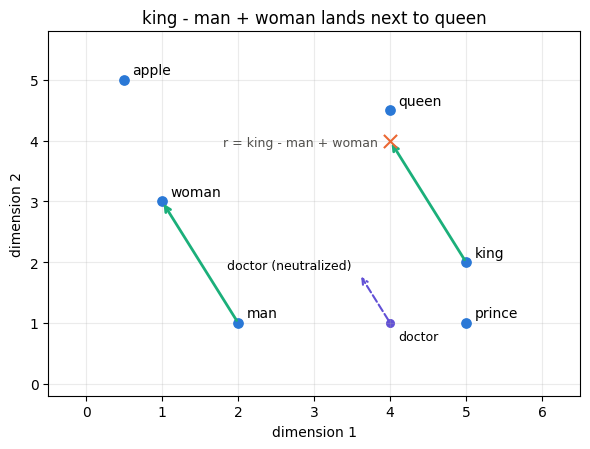

In [6]:
# Part A
A, B, C = np.array([2, 1.0]), np.array([10, 5.0]), np.array([3, 3.0])
check("d(A, B)", np.linalg.norm(A - B), "8.9443")
check("d(A, C)", np.linalg.norm(A - C), "2.2361")
check("cos(A, B)", cosine(A, B), "1.0000")
check("cos(A, C)", cosine(A, C), "0.9487")

# Part B
vec = {"man": (2, 1), "woman": (1, 3), "king": (5, 2), "queen": (4, 4.5), "prince": (5, 1), "apple": (0.5, 5)}
vec = {w: np.array(v, dtype=float) for w, v in vec.items()}
r = vec["king"] - vec["man"] + vec["woman"]
assert r.tolist() == [4.0, 4.0]
check("||r||", np.linalg.norm(r), "5.6569")
candidates = [w for w in vec if w not in ("king", "man", "woman")]      # always exclude the input words
hand = {"queen": ("0.5000", "0.9983"), "prince": ("3.1623", "0.8321"), "apple": ("3.6401", "0.7740")}
for w in candidates:
    check(f"distance(r, {w})", np.linalg.norm(r - vec[w]), hand[w][0])
    check(f"cos(r, {w})", cosine(r, vec[w]), hand[w][1])
best_euclid = min(candidates, key=lambda w: np.linalg.norm(r - vec[w]))
best_cos = max(candidates, key=lambda w: cosine(r, vec[w]))
assert best_euclid == best_cos == "queen"
print("nearest word:", best_cos)

# Part C
g = vec["woman"] - vec["man"]
doctor = np.array([4, 1.0])
e_bias = (doctor @ g) / (g @ g) * g
debiased = doctor - e_bias
assert np.allclose(e_bias, [0.4, -0.8]) and np.allclose(debiased, [3.6, 1.8])
check("debiased . g", debiased @ g, "0.0000")

# Figure: the analogy as arrows. The arrow man -> woman is added to king and lands on r, next to queen.
fig, ax = plt.subplots(figsize=(6, 4.6))
for w, v in vec.items():
    ax.scatter(*v, s=45, color="#2a78d6", zorder=3)
    ax.annotate(w, v, textcoords="offset points", xytext=(6, 4), fontsize=10)
ax.scatter(*r, s=90, marker="x", color="#eb6834", zorder=4)
ax.annotate("r = king - man + woman", r, textcoords="offset points", xytext=(-9, -4), ha="right", fontsize=9, color="#52514e")
arrow = dict(arrowstyle="->", color="#1baf7a", lw=2)
ax.annotate("", xy=vec["woman"], xytext=vec["man"], arrowprops=arrow)
ax.annotate("", xy=r, xytext=vec["king"], arrowprops=arrow)
ax.annotate("", xy=debiased, xytext=doctor, arrowprops=dict(arrowstyle="->", color="#6250d6", lw=1.5, ls="--"))
ax.scatter(*doctor, s=30, color="#6250d6"); ax.annotate("doctor", doctor, textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.annotate("doctor (neutralized)", debiased, textcoords="offset points", xytext=(-6, 4), ha="right", fontsize=9)
ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.2, 5.8)
ax.set_xlabel("dimension 1"); ax.set_ylabel("dimension 2")
ax.set_title("king - man + woman lands next to queen")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Try it yourself

1. Compute $\mathbf r_2 = \text{prince} - \text{man} + \text{woman}$ and the nearest word (excluding prince, man, woman) by Euclidean distance and by cosine.
2. Neutralize nurse $= (1, 4)$ with the same $\mathbf g$.

<details><summary>Answer</summary>

1. $\mathbf r_2 = (5 - 2 + 1,\ 1 - 1 + 3) = (4, 3)$, $\lVert\mathbf r_2\rVert = 5$.
   - king (5, 2): distance $\sqrt{1 + 1} = 1.4142$; cosine $\dfrac{20 + 6}{5 \times 5.3852} = 0.9656$
   - queen (4, 4.5): distance $\sqrt{0 + 2.25} = 1.5000$; cosine $\dfrac{16 + 13.5}{5 \times 6.0208} = 0.9799$
   - apple (0.5, 5): distance $\sqrt{12.25 + 4} = 4.0311$; cosine $\dfrac{2 + 15}{5 \times 5.0249} = 0.6766$

   Euclidean picks **king**, cosine picks **queen**: the two measures can disagree.
2. $\mathbf e\cdot\mathbf g = -1 + 8 = 7$; $\mathbf e_\text{bias} = \tfrac{7}{5}(-1, 2) = (-1.4, 2.8)$; debiased nurse $= (1 + 1.4,\ 4 - 2.8) = (2.4, 1.2)$.

</details>

**Exam tip:** always exclude the input words when you search for the analogy answer; in real embeddings the vector nearest to $\mathbf r$ is often "king" itself. To draw 300-dimensional vectors on paper, people first project them to 2-D with PCA (worked by hand in the ML numericals notebook).

## 6. Word translation with a matrix $R$, kNN, and locality-sensitive hashing

**What it is.** If English and French word vectors have a similar shape, one matrix $R$ can map English vectors onto French ones: $XR \approx Y$. We measure the error with the squared **Frobenius norm** (the sum of all squared entries). To translate a new word, map it with $R$ and find its **k nearest neighbours** (kNN) among French vectors. **Locality-sensitive hashing (LSH)** speeds up the search: vectors are put into buckets according to which side of a few planes they lie on, and we search only the query's bucket.

**Everyday analogy.** $R$ is like rotating a transparent city map until its streets line up with a second map. LSH is like a library sorted into sections: you look for your book only in the right section, not in the whole building.

**How it works.** Loss $= \lVert XR - Y\rVert_F^2$; gradient $= \frac{2}{m}X^\top(XR - Y)$ for the mean loss over $m$ words. LSH bit $h_i = 1$ if $\mathbf p_i\cdot\mathbf v \ge 0$, else 0; bucket $= \sum_i 2^{\,i-1} h_i$ (plane 1 is the $2^0$ bit).

### Problem

**A.** English rows: cat = (1, 2), dog = (3, 1); French rows: chat = (2.5, −1), chien = (1, −2); $R = \begin{bmatrix}0 & -1\\ 1 & 0\end{bmatrix}$ (each row vector $\mathbf x$ maps to $\mathbf xR$).
(a) Compute $XR$; (b) the loss $\lVert XR - Y\rVert_F^2$ and its mean over $m = 2$ words; (c) the gradient $\frac{2}{m}X^\top(XR - Y)$; (d) translate bird = (2, 2): compute $\mathbf xR$ and its nearest French word by cosine among

| French word | vector |
|---|---|
| chat | (2.5, −1) |
| chien | (1, −2) |
| oiseau | (1.8, −2.1) |
| maison | (−1, 1) |
| arbre | (0.5, −2.5) |
| ville | (−2, −1) |

**B.** LSH with two planes through the origin, with normal vectors $\mathbf p_1 = (1, 2)$ and $\mathbf p_2 = (2, -1)$. Put every French word and the query (the mapped bird vector) into a bucket, then search only the query's bucket.

### Solution by hand

**Part A**

Step 1: $XR$, row by row: $\mathbf xR = (x_1 \cdot 0 + x_2 \cdot 1,\ x_1 \cdot (-1) + x_2 \cdot 0) = (x_2, -x_1)$.
- cat: $(1, 2) \to (2, -1)$; dog: $(3, 1) \to (1, -3)$

Step 2: $XR - Y = \begin{bmatrix}2 - 2.5 & -1 - (-1)\\ 1 - 1 & -3 - (-2)\end{bmatrix} = \begin{bmatrix}-0.5 & 0\\ 0 & -1\end{bmatrix}$
$\lVert XR - Y\rVert_F^2 = 0.25 + 0 + 0 + 1 = $ **1.25**; mean over $m = 2$ words: $1.25 / 2 = $ **0.625**.

Step 3: gradient. $X^\top = \begin{bmatrix}1 & 3\\ 2 & 1\end{bmatrix}$,
$X^\top(XR - Y) = \begin{bmatrix}1(-0.5) + 3(0) & 1(0) + 3(-1)\\ 2(-0.5) + 1(0) & 2(0) + 1(-1)\end{bmatrix} = \begin{bmatrix}-0.5 & -3\\ -1 & -1\end{bmatrix}$, and $\frac{2}{m} = 1$, so the gradient is the same matrix. One gradient-descent step would be $R \leftarrow R - \alpha \cdot \text{gradient}$.

Step 4: translate bird. $\mathbf t = (2, 2)R = (2, -2)$, $\lVert\mathbf t\rVert = \sqrt 8 = 2.8284$.

| French word | $\mathbf v\cdot\mathbf t$ | $\lVert\mathbf v\rVert$ | cosine |
|---|---|---|---|
| chat | $5 + 2 = 7$ | 2.6926 | $7 / (2.8284 \times 2.6926) = 0.9191$ |
| chien | $2 + 4 = 6$ | 2.2361 | 0.9487 |
| oiseau | $3.6 + 4.2 = 7.8$ | 2.7659 | **0.9971** |
| maison | $-2 - 2 = -4$ | 1.4142 | −1.0000 |
| arbre | $1 + 5 = 6$ | 2.5495 | 0.8321 |
| ville | $-4 + 2 = -2$ | 2.2361 | −0.3162 |

1-nearest neighbour: **oiseau** (bird → oiseau). With $k = 2$: oiseau and chien.

**Part B: LSH buckets.** $h_1 = [\mathbf p_1\cdot\mathbf v \ge 0]$, $h_2 = [\mathbf p_2\cdot\mathbf v \ge 0]$, bucket $= h_1 + 2h_2$.

| vector | $\mathbf p_1\cdot\mathbf v = v_1 + 2v_2$ | $\mathbf p_2\cdot\mathbf v = 2v_1 - v_2$ | $h_1$ | $h_2$ | bucket |
|---|---|---|---|---|---|
| chat (2.5, −1) | $2.5 - 2 = 0.5$ | $5 + 1 = 6$ | 1 | 1 | 3 |
| chien (1, −2) | $1 - 4 = -3$ | $2 + 2 = 4$ | 0 | 1 | 2 |
| oiseau (1.8, −2.1) | $1.8 - 4.2 = -2.4$ | $3.6 + 2.1 = 5.7$ | 0 | 1 | 2 |
| maison (−1, 1) | $-1 + 2 = 1$ | $-2 - 1 = -3$ | 1 | 0 | 1 |
| arbre (0.5, −2.5) | $0.5 - 5 = -4.5$ | $1 + 2.5 = 3.5$ | 0 | 1 | 2 |
| ville (−2, −1) | $-2 - 2 = -4$ | $-4 + 1 = -3$ | 0 | 0 | 0 |
| **query (2, −2)** | $2 - 4 = -2$ | $4 + 2 = 6$ | 0 | 1 | **2** |

The query lands in bucket 2 = {chien, oiseau, arbre}. We compute only 3 cosines instead of 6 and still find **oiseau** (0.9971). LSH is *approximate*: a good neighbour just across a plane is missed (chat, cosine 0.9191, sits in bucket 3). Real systems use several independent sets of planes to reduce such misses.

In [7]:
X = np.array([[1, 2], [3, 1.0]])                  # cat, dog
Y = np.array([[2.5, -1], [1, -2.0]])              # chat, chien
R = np.array([[0, -1], [1, 0.0]])
XR = X @ R
assert XR.tolist() == [[2, -1], [1, -3]]
diff = XR - Y
check("||XR - Y||_F^2", (diff ** 2).sum(), "1.25")
check("mean loss over m=2", (diff ** 2).sum() / 2, "0.625")
grad = 2 / len(X) * X.T @ diff
assert np.allclose(grad, [[-0.5, -3], [-1, -1]])

french = {"chat": (2.5, -1), "chien": (1, -2), "oiseau": (1.8, -2.1),
          "maison": (-1, 1), "arbre": (0.5, -2.5), "ville": (-2, -1)}
french = {w: np.array(v, dtype=float) for w, v in french.items()}
t = np.array([2, 2.0]) @ R
assert t.tolist() == [2, -2]
hand_cos = {"chat": "0.9191", "chien": "0.9487", "oiseau": "0.9971", "maison": "-1.0000", "arbre": "0.8321", "ville": "-0.3162"}
for w, v in french.items():
    check(f"cos(bird R, {w})", cosine(t, v), hand_cos[w])
ranked = sorted(french, key=lambda w: -cosine(t, french[w]))
assert ranked[:2] == ["oiseau", "chien"]
print("k=2 nearest neighbours:", ranked[:2])

# LSH: one bit per plane, plane 1 is the 2^0 bit
planes = np.array([[1, 2], [2, -1.0]])
def bucket(v):
    bits = (planes @ v >= 0).astype(int)
    return int(sum(b * 2 ** i for i, b in enumerate(bits)))
buckets = {w: bucket(v) for w, v in french.items()}
print("buckets:", buckets, "| query bucket:", bucket(t))
assert buckets == {"chat": 3, "chien": 2, "oiseau": 2, "maison": 1, "arbre": 2, "ville": 0} and bucket(t) == 2
same_bucket = [w for w in french if buckets[w] == bucket(t)]
assert max(same_bucket, key=lambda w: cosine(t, french[w])) == "oiseau"
print("searched only", same_bucket, "-> oiseau")

OK  ||XR - Y||_F^2                               code = 1.250000     hand = 1.25
OK  mean loss over m=2                           code = 0.625000     hand = 0.625
OK  cos(bird R, chat)                            code = 0.919145     hand = 0.9191
OK  cos(bird R, chien)                           code = 0.948683     hand = 0.9487
OK  cos(bird R, oiseau)                          code = 0.997054     hand = 0.9971
OK  cos(bird R, maison)                          code = -1.000000    hand = -1.0000
OK  cos(bird R, arbre)                           code = 0.832050     hand = 0.8321
OK  cos(bird R, ville)                           code = -0.316228    hand = -0.3162
k=2 nearest neighbours: ['oiseau', 'chien']
buckets: {'chat': 3, 'chien': 2, 'oiseau': 2, 'maison': 1, 'arbre': 2, 'ville': 0} | query bucket: 2
searched only ['chien', 'oiseau', 'arbre'] -> oiseau


### Try it yourself

1. Compute $\lVert XR - Y\rVert_F^2$ for the "do nothing" matrix $R = I$ (identity). Is the rotation better?
2. Which LSH bucket does $\mathbf v = (-2, 3)$ fall into with the same two planes?

<details><summary>Answer</summary>

1. With $R = I$: $X - Y = \begin{bmatrix}1 - 2.5 & 2 + 1\\ 3 - 1 & 1 + 2\end{bmatrix} = \begin{bmatrix}-1.5 & 3\\ 2 & 3\end{bmatrix}$, loss $= 2.25 + 9 + 4 + 9 = 24.25$. The rotation (loss 1.25) is far better.
2. $\mathbf p_1\cdot\mathbf v = -2 + 6 = 4 \ge 0 \Rightarrow h_1 = 1$; $\mathbf p_2\cdot\mathbf v = -4 - 3 = -7 < 0 \Rightarrow h_2 = 0$; bucket $= 1 + 2 \times 0 = 1$.

</details>

**Exam tip:** with $n$ planes there are $2^n$ buckets. State which plane gives the $2^0$ bit and whether a dot product of exactly 0 counts as side 1; different books use different conventions.

## 7. Minimum edit distance (Levenshtein)

**What it is.** The smallest total cost of insertions, deletions and substitutions that turns one string into another.

**Everyday analogy.** The fewest key presses needed to fix a typo.

**How it works.** Fill a table $D$ where $D[i, j]$ is the distance between the first $i$ letters of the source and the first $j$ letters of the target ("#" is the empty string):

$$D[i, 0] = i,\qquad D[0, j] = j,\qquad D[i, j] = \min\begin{cases} D[i-1, j] + 1 & \text{(delete)}\\ D[i, j-1] + 1 & \text{(insert)}\\ D[i-1, j-1] + \begin{cases}0 & \text{if the letters are equal}\\ \text{sub} & \text{otherwise}\end{cases} & \text{(substitute)}\end{cases}$$

### Problem

Turn "play" into "stay" with insert = delete = 1 and **substitution = 2** (the convention of Jurafsky & Martin). Fill the whole table. Then give the answer with substitution = 1 (classic Levenshtein).

### Solution by hand

**Step 1: the table** (rows = source "#play", columns = target "#stay", substitution cost 2):

| | # | s | t | a | y |
|---|---|---|---|---|---|
| **#** | 0 | 1 | 2 | 3 | 4 |
| **p** | 1 | 2 | 3 | 4 | 5 |
| **l** | 2 | 3 | 4 | 5 | 6 |
| **a** | 3 | 4 | 5 | 4 | 5 |
| **y** | 4 | 5 | 6 | 5 | 4 |

**Step 2: a few cells worked out**
- $D[\text{p}, \text{s}]$: p ≠ s → $\min(D[\#, \text{s}] + 1,\ D[\text{p}, \#] + 1,\ D[\#, \#] + 2) = \min(2, 2, 2) = 2$
- $D[\text{l}, \text{t}]$: l ≠ t → $\min(D[\text{p}, \text{t}] + 1,\ D[\text{l}, \text{s}] + 1,\ D[\text{p}, \text{s}] + 2) = \min(3 + 1, 3 + 1, 2 + 2) = 4$
- $D[\text{a}, \text{a}]$: equal letters → $\min(D[\text{l}, \text{a}] + 1,\ D[\text{a}, \text{t}] + 1,\ D[\text{l}, \text{t}] + 0) = \min(6, 6, 4) = 4$
- $D[\text{y}, \text{y}]$: equal letters → $\min(D[\text{a}, \text{y}] + 1,\ D[\text{y}, \text{a}] + 1,\ D[\text{a}, \text{a}] + 0) = \min(6, 6, 4) = 4$

**Step 3: answers**
- substitution = 2: distance **4** (substitute p→s and l→t at cost 2 each; deleting 2 letters and inserting 2 letters costs the same).
- substitution = 1: distance **2** (the two substitutions now cost 1 each).

In [8]:
def edit_distance(src, tgt, sub_cost):
    D = np.zeros((len(src) + 1, len(tgt) + 1), dtype=int)
    D[:, 0] = range(len(src) + 1)                 # deleting everything
    D[0, :] = range(len(tgt) + 1)                 # inserting everything
    for i in range(1, len(src) + 1):
        for j in range(1, len(tgt) + 1):
            same = src[i - 1] == tgt[j - 1]
            D[i, j] = min(D[i - 1, j] + 1,                        # delete
                          D[i, j - 1] + 1,                        # insert
                          D[i - 1, j - 1] + (0 if same else sub_cost))   # substitute / match
    return D

D2 = edit_distance("play", "stay", sub_cost=2)
print("substitution cost 2:\n", D2)
assert D2.tolist() == [[0, 1, 2, 3, 4], [1, 2, 3, 4, 5], [2, 3, 4, 5, 6], [3, 4, 5, 4, 5], [4, 5, 6, 5, 4]]
check("edit distance play->stay (sub=2)", D2[-1, -1], 4)
D1 = edit_distance("play", "stay", sub_cost=1)
print("substitution cost 1:\n", D1)
check("edit distance play->stay (sub=1)", D1[-1, -1], 2)

substitution cost 2:
 [[0 1 2 3 4]
 [1 2 3 4 5]
 [2 3 4 5 6]
 [3 4 5 4 5]
 [4 5 6 5 4]]
OK  edit distance play->stay (sub=2)             code = 4.000000     hand = 4
substitution cost 1:
 [[0 1 2 3 4]
 [1 1 2 3 4]
 [2 2 2 3 4]
 [3 3 3 2 3]
 [4 4 4 3 2]]
OK  edit distance play->stay (sub=1)             code = 2.000000     hand = 2


### Try it yourself

Compute the edit distance from "bake" to "back" with substitution cost 1 and with substitution cost 2.

<details><summary>Answer</summary>

Both answers are **2**. With cost 1: substitute k→c and e→k (or insert c and delete e). With cost 2: insert c (1) and delete e (1) = 2, cheaper than two substitutions (4). Table (cost 2), rows "#bake", columns "#back": last row is 4, 3, 2, 3, **2**.

</details>

**Common mistake:** forgetting the empty-string row and column (#), or using substitution cost 1 when the question says 2.

## 8. Autocorrect: candidate words and their probabilities

**What it is.** For a typo, generate every string one edit away (delete a letter, swap two neighbouring letters, replace a letter, insert a letter), keep the ones that are real words, and pick the most probable one: $P(w) = \dfrac{\text{count}(w)}{N}$.

**Everyday analogy.** A friend reading your rushed text message guesses the most common real word that is one slip of the finger away from what you typed.

**How it works.** For a word of length $n$ and an alphabet of 26 letters: $n$ deletes, $n - 1$ swaps, $25n$ replaces (by a *different* letter), $26(n + 1)$ inserts.

### Problem

The user typed "dag". (a) How many candidate strings does one edit produce? (b) A corpus of $N = 1{,}000$ tokens has these counts:

| word | count |
|---|---|
| the | 60 |
| day | 40 |
| go | 30 |
| dog | 25 |
| bag | 12 |
| drag | 6 |
| dig | 4 |
| dagger | 2 |

Which words are one edit away from "dag"? Compute $P(w)$ for each and choose the correction.

### Solution by hand

**Step 1: number of one-edit strings** for $n = 3$:
- deletes: $n = 3$ (ag, dg, da)
- swaps: $n - 1 = 2$ (adg, dga)
- replaces: $25n = 75$
- inserts: $26(n + 1) = 104$
- total $= 3 + 2 + 75 + 104 = $ **184** strings. A few are duplicates: inserting "a" just before or just after the existing "a" both give "daag" (the same happens with "d" and "g"), so there are 181 different strings.

**Step 2: keep only real words**
- day (replace g→y), dog (replace a→o), bag (replace d→b), dig (replace a→i), drag (insert r)
- not candidates: the and go (2 or more edits away), dagger (3 inserts)

**Step 3: probabilities** $P(w) = \text{count}/1000$:

| candidate | edit | $P(w)$ |
|---|---|---|
| day | replace | 40/1000 = 0.0400 |
| dog | replace | 25/1000 = 0.0250 |
| bag | replace | 12/1000 = 0.0120 |
| drag | insert | 6/1000 = 0.0060 |
| dig | replace | 4/1000 = 0.0040 |

The correction is **day**.

In [9]:
import string

def edits1(word):
    letters = string.ascii_lowercase
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [a + b[1:] for a, b in splits if b]
    swaps = [a + b[1] + b[0] + b[2:] for a, b in splits if len(b) > 1]
    replaces = [a + c + b[1:] for a, b in splits if b for c in letters if c != b[0]]
    inserts = [a + c + b for a, b in splits for c in letters]
    return deletes, swaps, replaces, inserts

dels, swaps, reps, ins = edits1("dag")
for name, lst, hand in [("deletes", dels, 3), ("swaps", swaps, 2), ("replaces", reps, 75), ("inserts", ins, 104)]:
    check(f"number of {name}", len(lst), hand)
all_edits = dels + swaps + reps + ins
check("total one-edit strings", len(all_edits), 184)
check("distinct one-edit strings", len(set(all_edits)), 181)

counts = {"the": 60, "day": 40, "go": 30, "dog": 25, "bag": 12, "drag": 6, "dig": 4, "dagger": 2}
candidates = sorted(set(all_edits) & set(counts), key=lambda w: -counts[w])
print("candidates:", {w: counts[w] / 1000 for w in candidates})
assert candidates == ["day", "dog", "bag", "drag", "dig"]
check("P(day)", counts["day"] / 1000, "0.0400")
print("correction:", candidates[0])

OK  number of deletes                            code = 3.000000     hand = 3
OK  number of swaps                              code = 2.000000     hand = 2
OK  number of replaces                           code = 75.000000    hand = 75
OK  number of inserts                            code = 104.000000   hand = 104
OK  total one-edit strings                       code = 184.000000   hand = 184
OK  distinct one-edit strings                    code = 181.000000   hand = 181
candidates: {'day': 0.04, 'dog': 0.025, 'bag': 0.012, 'drag': 0.006, 'dig': 0.004}
OK  P(day)                                       code = 0.040000     hand = 0.0400
correction: day


### Try it yourself

The user typed "teh". Counts (corpus of 1,000 tokens): the 60, then 12, ten 9, tea 7, tech 3, eh 1. Which are one edit away, and what is the correction?

<details><summary>Answer</summary>

One edit away: the (swap e,h), ten (replace h→n), tea (replace h→a), tech (insert c), eh (delete t). "then" needs two edits (swap, then insert n), so it is not a candidate. Best: **the**, $P = 60/1000 = 0.0600$.

</details>

**Exam tip:** the full *noisy-channel* model chooses $\arg\max_w P(\text{typo}\mid w)\,P(w)$, i.e. it also asks how likely that particular slip is. Simple autocorrect uses $P(w)$ only. If no word is one edit away, try two edits.

## 9. N-gram language models: MLE, add-one, add-k, backoff, interpolation, perplexity

**What it is.** A **bigram** model predicts the next word from the previous one: $P(w\mid\text{prev}) = \dfrac{C(\text{prev}\ w)}{C(\text{prev})}$ (MLE = maximum-likelihood estimate = count and divide). A sentence's probability is the product of its bigram probabilities. **Perplexity** measures how surprised the model is (lower is better).

**Everyday analogy.** A phone keyboard that suggests the next word using only the word you just typed.

**How it works.** Count, divide, multiply. Unseen pairs get probability 0, so we **smooth** (add-one, add-$k$), **back off** to the unigram, or **interpolate** bigram and unigram estimates.

### Problem

Corpus (with sentence markers):

| # | sentence |
|---|---|
| 1 | `<s>` we eat rice `</s>` |
| 2 | `<s>` we eat bread `</s>` |
| 3 | `<s>` they eat rice `</s>` |
| 4 | `<s>` we cook rice `</s>` |

Conventions: `<s>` is never predicted, `</s>` is. Unigram counts use every token after `<s>` ($N = 16$). The vocabulary for smoothing is {we, they, eat, cook, rice, bread, `</s>`}, so $|V| = 7$.

(a) Unigram probabilities. (b) Bigram MLE probability of "`<s>` we eat rice `</s>`". (c) Probability of the test sentence "`<s>` they cook rice `</s>`" with MLE and with add-one smoothing. (d) Perplexity of the test sentence with add-one. (e) Estimate $P(\text{cook}\mid\text{they})$ with add-$k$ ($k = 0.5$), stupid backoff (factor 0.4) and linear interpolation ($\lambda_\text{bi} = 0.8$, $\lambda_\text{uni} = 0.2$); also interpolate $P(\text{eat}\mid\text{they})$.

### Solution by hand

**Step 1: unigrams.** Counts: we 3, they 1, eat 3, cook 1, rice 3, bread 1, `</s>` 4 → $N = 16$.
$P(\text{we}) = P(\text{eat}) = P(\text{rice}) = 3/16 = 0.1875$; $P(\text{they}) = P(\text{cook}) = P(\text{bread}) = 1/16 = 0.0625$; $P(\langle /s\rangle) = 4/16 = 0.2500$.

**Step 2: bigram counts.** `<s>` we 3, `<s>` they 1, we eat 2, we cook 1, they eat 1, eat rice 2, eat bread 1, cook rice 1, rice `</s>` 3, bread `</s>` 1.
History counts $C(\text{prev})$: `<s>` 4, we 3, they 1, eat 3, cook 1, rice 3, bread 1.

$P(\text{we eat rice}) = P(\text{we}\mid\langle s\rangle)\,P(\text{eat}\mid\text{we})\,P(\text{rice}\mid\text{eat})\,P(\langle /s\rangle\mid\text{rice}) = \tfrac34 \times \tfrac23 \times \tfrac23 \times \tfrac33 = 0.75 \times 0.6667 \times 0.6667 \times 1 = $ **0.3333**

**Step 3: the test sentence "they cook rice".**
- MLE: $P(\text{they}\mid\langle s\rangle) = 1/4$, but $P(\text{cook}\mid\text{they}) = 0/1 = 0$ → the whole sentence gets probability **0**.
- Add-one: $P(w\mid\text{prev}) = \dfrac{C(\text{prev}\ w) + 1}{C(\text{prev}) + |V|}$

| bigram | count | add-one probability |
|---|---|---|
| `<s>` they | 1 | $(1 + 1)/(4 + 7) = 2/11 = 0.1818$ |
| they cook | 0 | $(0 + 1)/(1 + 7) = 1/8 = 0.1250$ |
| cook rice | 1 | $(1 + 1)/(1 + 7) = 2/8 = 0.2500$ |
| rice `</s>` | 3 | $(3 + 1)/(3 + 7) = 4/10 = 0.4000$ |

$P = \tfrac{2}{11} \times \tfrac18 \times \tfrac28 \times \tfrac{4}{10} = \tfrac{1}{440} = $ **0.002273**

**Step 4: perplexity** $PP = P^{-1/M}$ with $M = 4$ predicted tokens (they, cook, rice, `</s>`):
$PP = 440^{1/4} = $ **4.5800**. In logs: $\ln P = -\ln 440 = -6.0868$; average $= -6.0868/4 = -1.5217$; $PP = e^{1.5217} = 4.5800$.
(For comparison, the MLE training sentence of Step 2 has $PP = 0.3333^{-1/4} = 3^{1/4} = 1.3161$.)

**Step 5: other fixes for the unseen bigram "they cook"**
- add-$k$, $k = 0.5$: $\dfrac{0 + 0.5}{1 + 0.5 \times 7} = \dfrac{0.5}{4.5} = $ **0.1111**
- stupid backoff: the bigram count is 0, so use $0.4 \times P(\text{cook}) = 0.4 \times 0.0625 = $ **0.0250** (a *score*, not a true probability: the scores do not add up to 1)
- interpolation: $0.8 \times P_\text{MLE}(\text{cook}\mid\text{they}) + 0.2 \times P(\text{cook}) = 0.8 \times 0 + 0.2 \times 0.0625 = $ **0.0125**
- interpolation for a seen bigram: $P(\text{eat}\mid\text{they}) = 0.8 \times 1 + 0.2 \times 0.1875 = 0.8 + 0.0375 = $ **0.8375**

In [10]:
corpus = ["we eat rice", "we eat bread", "they eat rice", "we cook rice"]
sents = [["<s>"] + s.split() + ["</s>"] for s in corpus]
uni = Counter(w for s in sents for w in s[1:])                    # everything after <s>
N_tok = sum(uni.values())
bi = Counter((a, b) for s in sents for a, b in zip(s, s[1:]))
hist = Counter(a for s in sents for a in s[:-1])                  # how often each word is a history
V_size = len(uni)
check("N (unigram tokens)", N_tok, 16)
check("|V|", V_size, 7)
check("P(rice)", uni["rice"] / N_tok, "0.1875")
check("P(cook)", uni["cook"] / N_tok, "0.0625")
check("P(</s>)", uni["</s>"] / N_tok, "0.2500")

def p_bigram(w, prev, k=0.0):                                     # k=0: MLE, k=1: add-one, k=0.5: add-k
    return (bi[(prev, w)] + k) / (hist[prev] + k * V_size)

def sentence_probs(sentence, k=0.0):
    s = ["<s>"] + sentence.split() + ["</s>"]
    return [p_bigram(b, a, k) for a, b in zip(s, s[1:])]

check("P(we eat rice) MLE", np.prod(sentence_probs("we eat rice")), "0.3333")
check("PP(we eat rice) MLE", np.prod(sentence_probs("we eat rice")) ** (-1 / 4), "1.3161")
check("P(they cook rice) MLE", np.prod(sentence_probs("they cook rice")), 0)
probs = sentence_probs("they cook rice", k=1)
for (name, hand), p in zip([("P(they|<s>)", "0.1818"), ("P(cook|they)", "0.1250"),
                            ("P(rice|cook)", "0.2500"), ("P(</s>|rice)", "0.4000")], probs):
    check(name + " add-one", p, hand)
P_test = np.prod(probs)
check("P(they cook rice) add-one", P_test, "0.002273")
check("ln P", math.log(P_test), "-6.0868")
check("perplexity add-one", P_test ** (-1 / len(probs)), "4.5800")

check("add-k (k=0.5) P(cook|they)", p_bigram("cook", "they", k=0.5), "0.1111")
check("stupid backoff S(cook|they)", 0.4 * uni["cook"] / N_tok, "0.0250")
interp = lambda w, prev: 0.8 * p_bigram(w, prev) + 0.2 * uni[w] / N_tok
check("interpolated P(cook|they)", interp("cook", "they"), "0.0125")
check("interpolated P(eat|they)", interp("eat", "they"), "0.8375")

OK  N (unigram tokens)                           code = 16.000000    hand = 16
OK  |V|                                          code = 7.000000     hand = 7
OK  P(rice)                                      code = 0.187500     hand = 0.1875
OK  P(cook)                                      code = 0.062500     hand = 0.0625
OK  P(</s>)                                      code = 0.250000     hand = 0.2500
OK  P(we eat rice) MLE                           code = 0.333333     hand = 0.3333
OK  PP(we eat rice) MLE                          code = 1.316074     hand = 1.3161
OK  P(they cook rice) MLE                        code = 0.000000     hand = 0
OK  P(they|<s>) add-one                          code = 0.181818     hand = 0.1818
OK  P(cook|they) add-one                         code = 0.125000     hand = 0.1250
OK  P(rice|cook) add-one                         code = 0.250000     hand = 0.2500
OK  P(</s>|rice) add-one                         code = 0.400000     hand = 0.4000
OK  P(they cook ri

### Try it yourself

(a) Compute the MLE perplexity of "`<s>` they eat bread `</s>`". (b) Compute the add-one probability $P(\text{bread}\mid\text{we})$.

<details><summary>Answer</summary>

(a) $P = \tfrac14 \times \tfrac11 \times \tfrac13 \times \tfrac11 = \tfrac{1}{12} = 0.0833$; $PP = 12^{1/4} = 1.8612$.
(b) $\dfrac{C(\text{we bread}) + 1}{C(\text{we}) + |V|} = \dfrac{0 + 1}{3 + 7} = 0.1000$.

</details>

**Exam tip:** count `</s>` in $M$ (it is predicted) but not `<s>`. Perplexity is a "branching factor": $PP = 4.58$ means the model is as unsure as if it chose among about 4.6 equally likely words at every step.

## 10. HMM part-of-speech tagging and the Viterbi algorithm

**What it is.** A **Hidden Markov Model** has hidden states (here the tags N = noun, V = verb) that emit the visible words. It needs start probabilities $\pi$, transition probabilities $A$ (tag → next tag) and emission probabilities $B$ (tag → word). **Viterbi** finds the single most probable tag sequence using dynamic programming.

**Everyday analogy.** You cannot see the weather on past days (hidden), but you can read a diary of activities (visible: "swam", "read indoors") and work out the most likely weather sequence.

**How it works.**
$$v_1(j) = \pi(j)\,B(j, w_1),\qquad v_t(j) = \max_i \big[v_{t-1}(i)\,A(i \to j)\big]\,B(j, w_t)$$
and remember which $i$ gave the max (the **backpointer**). At the end, take the best final tag and follow the backpointers.

### Problem

Tagged training corpus:

| # | sentence |
|---|---|
| 1 | fish/N can/V swim/V |
| 2 | people/N can/V fish/V |
| 3 | people/N eat/V fish/N |
| 4 | fish/N eat/V food/N |
| 5 | people/N fish/V |
| 6 | eat/V fish/N |

(a) Estimate $\pi$, $A$ and $B$ by counting (MLE, no smoothing). (b) Run Viterbi on "fish eat fish". Many numbers here are exact fractions, so they are shown exactly.

### Solution by hand

**Step 1: start probabilities.** First tags: N, N, N, N, N, V → $\pi(\text{N}) = 5/6 = 0.8333$, $\pi(\text{V}) = 1/6 = 0.1667$.

**Step 2: transitions.** Tag pairs: S1 N→V, V→V; S2 N→V, V→V; S3 N→V, V→N; S4 N→V, V→N; S5 N→V; S6 V→N.
From N: N→V 5 times, N→N 0 times. From V: V→V 2 times, V→N 3 times.

| from \ to | N | V |
|---|---|---|
| N | 0/5 = 0 | 5/5 = 1 |
| V | 3/5 = 0.6 | 2/5 = 0.4 |

**Step 3: emissions.** N appears 8 times (fish 4, people 3, food 1); V appears 8 times (can 2, fish 2, swim 1, eat 3).

| | fish | people | food | can | swim | eat |
|---|---|---|---|---|---|---|
| N | 4/8 = 0.5 | 3/8 = 0.375 | 1/8 = 0.125 | 0 | 0 | 0 |
| V | 2/8 = 0.25 | 0 | 0 | 2/8 = 0.25 | 1/8 = 0.125 | 3/8 = 0.375 |

**Step 4: Viterbi for "fish eat fish"**

$t = 1$ (fish):
- $v_1(\text{N}) = \pi(\text{N})\,B(\text{N}, \text{fish}) = 0.8333 \times 0.5 = 0.4167$
- $v_1(\text{V}) = 0.1667 \times 0.25 = 0.0417$

$t = 2$ (eat):
- $v_2(\text{N}) = \max(0.4167 \times A(\text{N}\to\text{N}),\ 0.0417 \times A(\text{V}\to\text{N})) \times B(\text{N}, \text{eat}) = \max(0,\ 0.0250) \times 0 = 0$
- $v_2(\text{V}) = \max(0.4167 \times 1,\ 0.0417 \times 0.4) \times 0.375 = \max(0.4167,\ 0.0167) \times 0.375 = 0.15625$ (exactly 5/32), backpointer **N**

$t = 3$ (fish):
- $v_3(\text{N}) = \max(0 \times 0,\ 0.15625 \times 0.6) \times 0.5 = 0.09375 \times 0.5 = 0.046875$, backpointer **V**
- $v_3(\text{V}) = \max(0 \times 1,\ 0.15625 \times 0.4) \times 0.25 = 0.0625 \times 0.25 = 0.015625$, backpointer **V**

| | fish | eat | fish |
|---|---|---|---|
| N | 0.4167 | 0 | **0.046875** (from V) |
| V | 0.0417 | **0.15625** (from N) | 0.015625 (from V) |

**Step 5: backtrack.** Best last cell: N (0.046875 > 0.015625) → its backpointer is V at $t = 2$ → whose backpointer is N at $t = 1$.
Answer: **fish/N eat/V fish/N**, with path probability 0.046875 (= 3/64).

In [11]:
tagged = ["fish/N can/V swim/V", "people/N can/V fish/V", "people/N eat/V fish/N",
          "fish/N eat/V food/N", "people/N fish/V", "eat/V fish/N"]
data = [[tuple(tok.split("/")) for tok in s.split()] for s in tagged]
tags = ["N", "V"]
start = Counter(s[0][1] for s in data)
trans = Counter((a[1], b[1]) for s in data for a, b in zip(s, s[1:]))
emit = Counter((t, w) for s in data for w, t in s)
tag_count = Counter(t for s in data for _, t in s)
from_count = Counter(a for (a, _b) in trans.elements())

pi = {t: start[t] / len(data) for t in tags}
A = {(a, b): trans[(a, b)] / from_count[a] for a in tags for b in tags}
B = lambda t, w: emit[(t, w)] / tag_count[t]
check("pi(N)", pi["N"], "0.8333")
check("A(V->N)", A[("V", "N")], "0.6")
check("A(N->V)", A[("N", "V")], 1)
check("B(N, fish)", B("N", "fish"), "0.5")
check("B(V, eat)", B("V", "eat"), "0.375")

def viterbi(words):
    v = [{t: pi[t] * B(t, words[0]) for t in tags}]
    back = [{}]
    for w in words[1:]:
        col, bp = {}, {}
        for t in tags:
            best_prev = max(tags, key=lambda p: v[-1][p] * A[(p, t)])
            col[t] = v[-1][best_prev] * A[(best_prev, t)] * B(t, w)
            bp[t] = best_prev
        v.append(col); back.append(bp)
    last = max(tags, key=lambda t: v[-1][t])
    path = [last]
    for bp in reversed(back[1:]):
        path.append(bp[path[-1]])
    return v, path[::-1]

v, path = viterbi("fish eat fish".split())
for t_idx, col in enumerate(v, start=1):
    print(f"t={t_idx}:", {t: round(p, 6) for t, p in col.items()})
check("v1(N)", v[0]["N"], "0.4167")
check("v1(V)", v[0]["V"], "0.0417")
check("v2(N)", v[1]["N"], 0)
check("v2(V)", v[1]["V"], "0.15625")
check("v3(N)", v[2]["N"], "0.046875")
check("v3(V)", v[2]["V"], "0.015625")
assert path == ["N", "V", "N"]
print("best tags:", list(zip("fish eat fish".split(), path)))

OK  pi(N)                                        code = 0.833333     hand = 0.8333
OK  A(V->N)                                      code = 0.600000     hand = 0.6
OK  A(N->V)                                      code = 1.000000     hand = 1
OK  B(N, fish)                                   code = 0.500000     hand = 0.5
OK  B(V, eat)                                    code = 0.375000     hand = 0.375
t=1: {'N': 0.416667, 'V': 0.041667}
t=2: {'N': 0.0, 'V': 0.15625}
t=3: {'N': 0.046875, 'V': 0.015625}
OK  v1(N)                                        code = 0.416667     hand = 0.4167
OK  v1(V)                                        code = 0.041667     hand = 0.0417
OK  v2(N)                                        code = 0.000000     hand = 0
OK  v2(V)                                        code = 0.156250     hand = 0.15625
OK  v3(N)                                        code = 0.046875     hand = 0.046875
OK  v3(V)                                        code = 0.015625     hand = 0.0156

### Try it yourself

Run Viterbi on "fish can swim" with the same model.

<details><summary>Answer</summary>

- $t = 1$: $v_1(\text{N}) = 0.4167$, $v_1(\text{V}) = 0.0417$ (as before).
- $t = 2$ (can): $v_2(\text{V}) = \max(0.4167 \times 1,\ 0.0417 \times 0.4) \times 0.25 = 0.1042$ (from N); $v_2(\text{N}) = 0$ because $B(\text{N}, \text{can}) = 0$.
- $t = 3$ (swim): $v_3(\text{V}) = 0.1042 \times 0.4 \times 0.125 = 0.005208$ (from V); $v_3(\text{N}) = 0$.
- Answer: fish/N can/V swim/V, path probability 0.005208 (= 1/192).

</details>

**Common mistake:** forgetting $\pi$ for the first word, or adding probabilities instead of multiplying them (in log space you add the logs). Real taggers also smooth $A$ and $B$: the zeros above wipe out every path through them.

## 11. word2vec: skip-gram pairs, softmax, negative sampling, CBOW

**What it is.** word2vec learns word vectors by prediction. **Skip-gram** predicts each context word from the centre word; **CBOW** (continuous bag of words) predicts the centre word from the average of its context vectors. Each word has an *input* vector $\mathbf v$ and an *output* vector $\mathbf u$.

**Everyday analogy.** "You shall know a word by the company it keeps": a word's vector is shaped by the neighbours it usually has.

**How it works.**
- Skip-gram softmax: $P(o\mid c) = \dfrac{e^{\mathbf u_o\cdot\mathbf v_c}}{\sum_{w} e^{\mathbf u_w\cdot\mathbf v_c}}$, loss $= -\ln P(o\mid c)$.
- Negative sampling: $L = -\ln\sigma(\mathbf u_o\cdot\mathbf v_c) - \sum_{k} \ln\sigma(-\mathbf u_k\cdot\mathbf v_c)$ over a few sampled "noise" words $k$.
- CBOW: $\mathbf h = $ average of the context input vectors, then softmax of $\mathbf u_w\cdot\mathbf h$.

### Problem

(a) Sentence "we love hot green tea", window size $m = 2$: list the skip-gram (centre, context) pairs. How many are there?

(b) Centre word "hot" has input vector $\mathbf v_\text{hot} = (1.0, 0.5)$. Output vectors of a 5-word vocabulary:

| word | $\mathbf u_w$ |
|---|---|
| tea | (0.8, 0.4) |
| coffee | (0.6, 0.2) |
| hot | (0.2, 0.2) |
| cold | (0.0, 0.4) |
| car | (−0.5, 0.0) |

Compute $P(\text{tea}\mid\text{hot})$ with the full softmax, and the loss.

(c) Negative-sampling loss for the positive pair (hot, tea) with the negatives car and cold.

(d) CBOW: the context of "hot" (window 2) has input vectors we (0.2, 0.4), love (0.6, 0.0), green (0.4, 0.8), tea (1.0, 0.4). Compute $\mathbf h$ and $P(\text{hot}\mid\text{context})$ using the output vectors above.

### Solution by hand

**Step 1: skip-gram pairs** (each word with up to 2 neighbours on each side):

| centre | context words | pairs |
|---|---|---|
| we | love, hot | 2 |
| love | we, hot, green | 3 |
| hot | we, love, green, tea | 4 |
| green | love, hot, tea | 3 |
| tea | hot, green | 2 |

Total **14** pairs. Shortcut for a sentence of $T \ge m$ words: $2mT - m(m+1) = 2 \times 2 \times 5 - 2 \times 3 = 20 - 6 = 14$.

**Step 2: softmax.** Dot products $\mathbf u_w\cdot\mathbf v_\text{hot}$: tea $0.8 + 0.2 = 1.0$; coffee $0.6 + 0.1 = 0.7$; hot $0.2 + 0.1 = 0.3$; cold $0 + 0.2 = 0.2$; car $-0.5 + 0 = -0.5$.
Exponentials: $e^{1.0} = 2.7183$, $e^{0.7} = 2.0138$, $e^{0.3} = 1.3499$, $e^{0.2} = 1.2214$, $e^{-0.5} = 0.6065$; sum $= 7.9098$.
$P(\text{tea}\mid\text{hot}) = 2.7183 / 7.9098 = $ **0.3437**; loss $= -\ln 0.3437 = $ **1.0681**.

**Step 3: negative sampling** (only 3 dot products instead of the whole vocabulary):
- positive tea: $\sigma(1.0) = 0.7311$, $-\ln 0.7311 = 0.3133$
- negative car: $\sigma(-(-0.5)) = \sigma(0.5) = 0.6225$, $-\ln 0.6225 = 0.4741$
- negative cold: $\sigma(-0.2) = 0.4502$, $-\ln 0.4502 = 0.7981$
- $L = 0.3133 + 0.4741 + 0.7981 = $ **1.5855**

**Step 4: CBOW**
- $\mathbf h = \left(\dfrac{0.2 + 0.6 + 0.4 + 1.0}{4},\ \dfrac{0.4 + 0 + 0.8 + 0.4}{4}\right) = \left(\dfrac{2.2}{4}, \dfrac{1.6}{4}\right) = (0.55, 0.40)$
- scores $\mathbf u_w\cdot\mathbf h$: tea $0.44 + 0.16 = 0.60$; coffee $0.33 + 0.08 = 0.41$; hot $0.11 + 0.08 = 0.19$; cold $0 + 0.16 = 0.16$; car $-0.275$
- exponentials: 1.8221, 1.5068, 1.2092, 1.1735, 0.7596; sum $= 6.4713$
- $P(\text{hot}\mid\text{context}) = 1.2092 / 6.4713 = $ **0.1869**. These vectors are untrained; training would push this probability up.

In [12]:
sent = "we love hot green tea".split()
m = 2
pairs = [(sent[i], sent[j]) for i in range(len(sent))
         for j in range(max(0, i - m), min(len(sent), i + m + 1)) if j != i]
print(pairs)
check("number of skip-gram pairs", len(pairs), 14)
check("shortcut 2mT - m(m+1)", 2 * m * len(sent) - m * (m + 1), 14)

v_hot = np.array([1.0, 0.5])
U = {"tea": (0.8, 0.4), "coffee": (0.6, 0.2), "hot": (0.2, 0.2), "cold": (0.0, 0.4), "car": (-0.5, 0.0)}
U = {w: np.array(u) for w, u in U.items()}
words = list(U)
scores = np.array([U[w] @ v_hot for w in words])
check("sum of exponentials", np.exp(scores).sum(), "7.9098")
p = softmax(scores)
check("P(tea | hot)", p[words.index("tea")], "0.3437")
check("softmax loss", -math.log(p[words.index("tea")]), "1.0681")

pos_term = -math.log(sigmoid(U["tea"] @ v_hot))
neg_terms = [-math.log(sigmoid(-(U[k] @ v_hot))) for k in ("car", "cold")]
check("-ln sigma(u_tea . v)", pos_term, "0.3133")
check("-ln sigma(-u_car . v)", neg_terms[0], "0.4741")
check("-ln sigma(-u_cold . v)", neg_terms[1], "0.7981")
check("negative-sampling loss", pos_term + sum(neg_terms), "1.5855")

context_vectors = np.array([(0.2, 0.4), (0.6, 0.0), (0.4, 0.8), (1.0, 0.4)])   # we, love, green, tea
h = context_vectors.mean(axis=0)
assert np.allclose(h, [0.55, 0.40])
scores_cbow = np.array([U[w] @ h for w in words])
check("CBOW sum of exponentials", np.exp(scores_cbow).sum(), "6.4713")
check("CBOW P(hot | context)", softmax(scores_cbow)[words.index("hot")], "0.1869")

[('we', 'love'), ('we', 'hot'), ('love', 'we'), ('love', 'hot'), ('love', 'green'), ('hot', 'we'), ('hot', 'love'), ('hot', 'green'), ('hot', 'tea'), ('green', 'love'), ('green', 'hot'), ('green', 'tea'), ('tea', 'hot'), ('tea', 'green')]
OK  number of skip-gram pairs                    code = 14.000000    hand = 14
OK  shortcut 2mT - m(m+1)                        code = 14.000000    hand = 14
OK  sum of exponentials                          code = 7.909827     hand = 7.9098
OK  P(tea | hot)                                 code = 0.343659     hand = 0.3437
OK  softmax loss                                 code = 1.068106     hand = 1.0681
OK  -ln sigma(u_tea . v)                         code = 0.313262     hand = 0.3133
OK  -ln sigma(-u_car . v)                        code = 0.474077     hand = 0.4741
OK  -ln sigma(-u_cold . v)                       code = 0.798139     hand = 0.7981
OK  negative-sampling loss                       code = 1.585478     hand = 1.5855
OK  CBOW sum of expone

### Try it yourself

(a) How many skip-gram pairs does a 6-word sentence give with $m = 2$? (b) Recompute the negative-sampling loss with the negatives car and **coffee** instead of car and cold.

<details><summary>Answer</summary>

(a) $2 \times 2 \times 6 - 2 \times 3 = 24 - 6 = 18$.
(b) Coffee term: $\sigma(-0.7) = 0.3318$, $-\ln 0.3318 = 1.1032$. $L = 0.3133 + 0.4741 + 1.1032 = 1.8905$ (computed from unrounded terms). The negative "coffee" looks a lot like the true context "tea", so it is a harder negative and gives a bigger loss.

</details>

**Exam tip:** word2vec stores two matrices (input and output), each $|V| \times d$, so it has $2|V|d$ parameters: with $|V| = 10{,}000$ and $d = 300$ that is 6,000,000.

## 12. GloVe: the weighting function $f(X_{ij})$

**What it is.** GloVe learns vectors so that $\mathbf w_i\cdot\tilde{\mathbf w}_j + b_i + \tilde b_j \approx \ln X_{ij}$, where $X_{ij}$ is how often word $j$ appears near word $i$. Each pair is weighted by $f(X_{ij})$: rare pairs (noisy) count less, and very frequent pairs are capped so they do not dominate.

**Everyday analogy.** A teacher gives little weight to a one-question quiz, more to a longer test, but caps the weight of the final exam so it does not drown out everything else.

**How it works.**
$$f(x) = \begin{cases}(x / x_\text{max})^{\alpha} & x < x_\text{max}\\ 1 & x \ge x_\text{max}\end{cases},\qquad x_\text{max} = 100,\ \alpha = 0.75$$
$$J = \sum_{i,j} f(X_{ij})\,\big(\mathbf w_i\cdot\tilde{\mathbf w}_j + b_i + \tilde b_j - \ln X_{ij}\big)^2$$
Pairs with $X_{ij} = 0$ get $f(0) = 0$, so $\ln 0$ is never needed.

### Problem

(a) Compute $f(X)$ for $X = 0, 1, 10, 50, 100, 250$. (b) Compute one loss term with $X_{ij} = 10$, $\mathbf w_i\cdot\tilde{\mathbf w}_j = 1.5$, $b_i = 0.2$, $\tilde b_j = 0.1$.

### Solution by hand

**Step 1: weights**

| $X$ | $X / 100$ | $f(X)$ |
|---|---|---|
| 0 | 0 | 0 (pair skipped) |
| 1 | 0.01 | $0.01^{0.75} = 0.0316$ |
| 10 | 0.1 | $0.1^{0.75} = 0.1778$ |
| 50 | 0.5 | $0.5^{0.75} = 0.5946$ |
| 100 | 1 | 1 (cap reached) |
| 250 | 2.5 | 1 (capped) |

How to get a power on a basic calculator: $0.01^{0.75} = e^{0.75\ln 0.01} = e^{0.75 \times (-4.6052)} = e^{-3.4539} = 0.0316$.

**Step 2: one loss term**
- $\ln 10 = 2.3026$
- inside the bracket: $1.5 + 0.2 + 0.1 - 2.3026 = 1.8 - 2.3026 = -0.5026$
- squared: $(-0.5026)^2 = 0.2526$
- weighted: $f(10) \times 0.2526 = 0.1778 \times 0.2526 = $ **0.0449**

In [13]:
def glove_f(x, x_max=100, alpha=0.75):
    return (x / x_max) ** alpha if x < x_max else 1.0

for x, hand in [(0, 0), (1, "0.0316"), (10, "0.1778"), (50, "0.5946"), (100, 1), (250, 1)]:
    check(f"f({x})", glove_f(x), hand)
inner = 1.5 + 0.2 + 0.1 - math.log(10)
check("inner difference", inner, "-0.5026")
check("squared", inner ** 2, "0.2526")
check("weighted loss term", glove_f(10) * inner ** 2, "0.0449")

OK  f(0)                                         code = 0.000000     hand = 0
OK  f(1)                                         code = 0.031623     hand = 0.0316
OK  f(10)                                        code = 0.177828     hand = 0.1778
OK  f(50)                                        code = 0.594604     hand = 0.5946
OK  f(100)                                       code = 1.000000     hand = 1
OK  f(250)                                       code = 1.000000     hand = 1
OK  inner difference                             code = -0.502585    hand = -0.5026
OK  squared                                      code = 0.252592     hand = 0.2526
OK  weighted loss term                           code = 0.044918     hand = 0.0449


### Try it yourself

Compute $f(20)$ and the loss term for $X_{ij} = 20$, $\mathbf w_i\cdot\tilde{\mathbf w}_j = 2.0$, $b_i = 0.5$, $\tilde b_j = 0.3$.

<details><summary>Answer</summary>

$f(20) = 0.2^{0.75} = 0.2991$. $\ln 20 = 2.9957$; inside the bracket $2.0 + 0.5 + 0.3 - 2.9957 = -0.1957$; squared $0.03831$; term $= 0.2991 \times 0.03831 = 0.01146$.

</details>

**Exam tip:** $f$ rises from 0 to 1 and then stays flat at 1 for $X \ge x_\text{max}$. With $\alpha = 1$ the rising part would be a straight line; $\alpha = 0.75$ gives rare pairs a bit more weight than a straight line would.

## 13. RNN shapes and RNN vs GRU vs LSTM parameter counts

**What it is.** A recurrent neural network reads one token per time step and updates a hidden state:
$$a^{\langle t\rangle} = \tanh\big(W_{aa}\,a^{\langle t-1\rangle} + W_{ax}\,x^{\langle t\rangle} + b_a\big),\qquad \hat y^{\langle t\rangle} = \text{softmax}\big(W_{ya}\,a^{\langle t\rangle} + b_y\big)$$
The same weights are used at every step.

**Everyday analogy.** Reading a sentence word by word while updating a small notebook of what you remember so far.

**How it works.** Shapes follow from matrix multiplication: a weight matrix has (rows = size of what it produces) × (columns = size of what it reads). A GRU has 3 such blocks (update gate, reset gate, candidate) and an LSTM has 4 (input, forget, output gates and candidate), each the size of a plain RNN block.

### Problem

(a) Vocabulary of 10,000 words (one-hot inputs), hidden size $n_a = 100$, output = softmax over the vocabulary. Give the shapes of $x^{\langle t\rangle}$, $a^{\langle t\rangle}$, $W_{ax}$, $W_{aa}$, $b_a$, $W_{ya}$, $b_y$, $\hat y^{\langle t\rangle}$ for one example and for a batch of $m = 32$, and the total number of parameters.

(b) Parameters of one layer with input size $x = 50$ and hidden size $h = 64$ (one bias vector per block):
RNN $= h(h + x) + h$; GRU $= 3[h(h + x) + h]$; LSTM $= 4[h(h + x) + h]$. PyTorch keeps two bias vectors per block, so it adds $h$ more per block.

(c) One forward step with $n_a = 2$, a vocabulary of 3 words, $a^{\langle 0\rangle} = \mathbf 0$, $x^{\langle 1\rangle}$ = one-hot of word 2 $= (0, 1, 0)$,
$W_{ax} = \begin{bmatrix}0.5 & -1.0 & 0.2\\ 0.3 & 0.4 & -0.6\end{bmatrix}$, $b_a = (0.1, -0.2)$. Compute $a^{\langle 1\rangle}$.

### Solution by hand

**Step 1: shapes**

| quantity | one example | batch of $m = 32$ |
|---|---|---|
| $x^{\langle t\rangle}$ | (10000, 1) | (10000, 32) |
| $a^{\langle t\rangle}$ | (100, 1) | (100, 32) |
| $W_{ax}$ | (100, 10000) | same: weights do not depend on $m$ |
| $W_{aa}$ | (100, 100) | same |
| $b_a$ | (100, 1) | same (added to every column) |
| $W_{ya}$ | (10000, 100) | same |
| $b_y$ | (10000, 1) | same |
| $\hat y^{\langle t\rangle}$ | (10000, 1) | (10000, 32) |

Parameters: $W_{ax}$ 1,000,000 + $W_{aa}$ 10,000 + $b_a$ 100 + $W_{ya}$ 1,000,000 + $b_y$ 10,000 = **2,020,100**.

**Step 2: one layer, $x = 50$, $h = 64$**
- one block: $h(h + x) + h = 64 \times 114 + 64 = 7{,}296 + 64 = 7{,}360$
- RNN **7,360**; GRU $3 \times 7{,}360 = $ **22,080**; LSTM $4 \times 7{,}360 = $ **29,440**
- PyTorch (two biases, $+64$ per block): RNN 7,424; GRU 22,272; LSTM 29,696

**Step 3: one forward step.** $W_{aa}a^{\langle 0\rangle} = \mathbf 0$. Multiplying by a one-hot vector just picks a column: $W_{ax}x^{\langle 1\rangle}$ = column 2 = $(-1.0, 0.4)$.
$z = (-1.0 + 0.1,\ 0.4 - 0.2) = (-0.9, 0.2)$; $a^{\langle 1\rangle} = (\tanh(-0.9), \tanh(0.2)) = $ **(−0.7163, 0.1974)**

In [14]:
vocab_size, n_a, m = 10_000, 100, 32
shapes = {"x<t>": (vocab_size, m), "a<t>": (n_a, m), "W_ax": (n_a, vocab_size), "W_aa": (n_a, n_a),
          "b_a": (n_a, 1), "W_ya": (vocab_size, n_a), "b_y": (vocab_size, 1)}
x_t, a_prev = np.zeros(shapes["x<t>"]), np.zeros(shapes["a<t>"])
W_ax, W_aa, b_a = np.zeros(shapes["W_ax"]), np.zeros(shapes["W_aa"]), np.zeros(shapes["b_a"])
W_ya, b_y = np.zeros(shapes["W_ya"]), np.zeros(shapes["b_y"])
a_t = np.tanh(W_aa @ a_prev + W_ax @ x_t + b_a)      # numpy refuses if a shape is wrong
y_t = W_ya @ a_t + b_y
assert a_t.shape == (100, 32) and y_t.shape == (10_000, 32)
check("RNN language-model parameters", sum(np.prod(shapes[k]) for k in ["W_ax", "W_aa", "b_a", "W_ya", "b_y"]), 2_020_100)

def rnn_family_params(kind, x, h, biases=1):
    blocks = {"RNN": 1, "GRU": 3, "LSTM": 4}[kind]
    return blocks * (h * (h + x) + biases * h)

for kind, one_bias, two_bias in [("RNN", 7_360, 7_424), ("GRU", 22_080, 22_272), ("LSTM", 29_440, 29_696)]:
    check(f"{kind} params (one bias)", rnn_family_params(kind, 50, 64), one_bias)
    check(f"{kind} params (PyTorch, two biases)", rnn_family_params(kind, 50, 64, biases=2), two_bias)
try:
    import torch.nn as nn
    for kind, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
        assert sum(p.numel() for p in cls(50, 64).parameters()) == rnn_family_params(kind, 50, 64, biases=2)
    print("PyTorch layer sizes match the formulas.")
except ImportError:
    print("skipped: needs torch")

W_ax_small = np.array([[0.5, -1.0, 0.2], [0.3, 0.4, -0.6]])
b_small = np.array([0.1, -0.2])
a1 = np.tanh(W_ax_small @ np.array([0, 1, 0]) + b_small)
check("a<1>[0]", a1[0], "-0.7163")
check("a<1>[1]", a1[1], "0.1974")

OK  RNN language-model parameters                code = 2020100.000000 hand = 2020100
OK  RNN params (one bias)                        code = 7360.000000  hand = 7360
OK  RNN params (PyTorch, two biases)             code = 7424.000000  hand = 7424
OK  GRU params (one bias)                        code = 22080.000000 hand = 22080
OK  GRU params (PyTorch, two biases)             code = 22272.000000 hand = 22272
OK  LSTM params (one bias)                       code = 29440.000000 hand = 29440
OK  LSTM params (PyTorch, two biases)            code = 29696.000000 hand = 29696
skipped: needs torch
OK  a<1>[0]                                      code = -0.716298    hand = -0.7163
OK  a<1>[1]                                      code = 0.197375     hand = 0.1974


### Try it yourself

(a) Parameter counts (one bias) for $x = 300$, $h = 128$. (b) Continue part (c): with $W_{aa} = \begin{bmatrix}0.4 & 0\\ 0.1 & 0.5\end{bmatrix}$ and $x^{\langle 2\rangle} = (0, 0, 1)$, compute $a^{\langle 2\rangle}$.

<details><summary>Answer</summary>

(a) One block $= 128 \times 428 + 128 = 54{,}912$ → RNN 54,912; GRU 164,736; LSTM 219,648 (PyTorch: 55,040; 165,120; 220,160).
(b) $W_{aa}a^{\langle 1\rangle} = (0.4 \times (-0.7163),\ 0.1 \times (-0.7163) + 0.5 \times 0.1974) = (-0.2865, 0.0271)$; $W_{ax}x^{\langle 2\rangle}$ = column 3 = $(0.2, -0.6)$.
$z = (-0.2865 + 0.2 + 0.1,\ 0.0271 - 0.6 - 0.2) = (0.0135, -0.7729)$; $a^{\langle 2\rangle} = (\tanh 0.0135, \tanh(-0.7729)) = (0.0135, -0.6486)$.

</details>

**Exam tip:** the number of parameters does not depend on the sequence length (weights are shared over time). A one-hot input times $W_{ax}$ just selects a column, which is why embedding layers are implemented as table lookups.

## 14. Language-model loss, perplexity, sampling and temperature

**What it is.** A neural language model outputs a probability for every possible next token. Training minimizes the average **cross-entropy** $-\ln p(\text{correct next token})$; **perplexity** $= e^{\text{average loss}}$. To generate text we **sample** the next token from the distribution; **temperature** $T$ sharpens ($T < 1$) or flattens ($T > 1$) it: $p_i \propto e^{z_i / T}$.

**Everyday analogy.** A weather forecaster is scored by how much probability they gave to the weather that actually happened. Sampling is like rolling a loaded die whose faces are the words.

**How it works.** Loss per step $= -\ln p_t$; average over the $T$ steps; perplexity $= e^{\text{average}}$. Sampling with a random number $u \in [0, 1)$: walk along the cumulative probabilities and stop at the first one that is greater than $u$.

### Problem

(a) At 4 steps the model gives the correct next token probabilities 0.5, 0.25, 0.8, 0.4. Compute each loss, the total, the average, the perplexity, and the same in bits.
(b) The next-token distribution over [a, the, my, `</s>`] is [0.1, 0.5, 0.3, 0.1] and the random number is $u = 0.72$. Which token is sampled?
(c) Logits $z = [2, 1, 0]$: compute the softmax at $T = 1$, $T = 0.5$ and $T = 2$.

### Solution by hand

**Step 1: cross-entropy and perplexity**
- losses: $-\ln 0.5 = 0.6931$, $-\ln 0.25 = 1.3863$, $-\ln 0.8 = 0.2231$, $-\ln 0.4 = 0.9163$
- total $= -\ln(0.5 \times 0.25 \times 0.8 \times 0.4) = -\ln 0.04 = $ **3.2189**
- average $= 3.2189 / 4 = $ **0.8047**
- perplexity $= e^{0.8047} = $ **2.2361** (the same as $0.04^{-1/4} = 25^{1/4} = \sqrt 5$)
- in bits: $-\log_2$ gives 1, 2, 0.3219, 1.3219; average $= 1.1610$ bits; $2^{1.1610} = 2.2361$ (the same perplexity)

**Step 2: sampling.** Cumulative probabilities: a 0.1, the 0.6, my 0.9, `</s>` 1.0. $u = 0.72$ is above 0.6 and not above 0.9, so the sampled token is **my**.

**Step 3: temperature**

| $T$ | $z / T$ | exponentials | sum | probabilities |
|---|---|---|---|---|
| 1 | [2, 1, 0] | 7.3891, 2.7183, 1 | 11.1073 | [0.6652, 0.2447, 0.0900] |
| 0.5 | [4, 2, 0] | 54.5982, 7.3891, 1 | 62.9872 | [0.8668, 0.1173, 0.0159] |
| 2 | [1, 0.5, 0] | 2.7183, 1.6487, 1 | 5.3670 | [0.5065, 0.3072, 0.1863] |

Low temperature → sharper, almost greedy; high temperature → flatter, more random text.

In [15]:
p_correct = np.array([0.5, 0.25, 0.8, 0.4])
losses = -np.log(p_correct)
for p, l, hand in zip(p_correct, losses, ["0.6931", "1.3863", "0.2231", "0.9163"]):
    check(f"-ln {p}", l, hand)
check("total loss", losses.sum(), "3.2189")
check("average loss", losses.mean(), "0.8047")
check("perplexity e^avg", math.exp(losses.mean()), "2.2361")
check("average bits", (-np.log2(p_correct)).mean(), "1.1610")
check("perplexity 2^bits", 2 ** (-np.log2(p_correct)).mean(), "2.2361")

tokens = ["a", "the", "my", "</s>"]
cdf = np.cumsum([0.1, 0.5, 0.3, 0.1])
sampled = tokens[int(np.searchsorted(cdf, 0.72, side="right"))]   # first cumulative value > u
assert sampled == "my"
print("sampled with u=0.72:", sampled)

z = np.array([2.0, 1.0, 0.0])
for T, hand in [(1, ["0.6652", "0.2447", "0.0900"]), (0.5, ["0.8668", "0.1173", "0.0159"]), (2, ["0.5065", "0.3072", "0.1863"])]:
    probs = softmax(z / T)
    check(f"T={T} sum of exponentials", np.exp(z / T).sum(), {1: "11.1073", 0.5: "62.9872", 2: "5.3670"}[T])
    for i in range(3):
        check(f"T={T} p[{i}]", probs[i], hand[i])

OK  -ln 0.5                                      code = 0.693147     hand = 0.6931
OK  -ln 0.25                                     code = 1.386294     hand = 1.3863
OK  -ln 0.8                                      code = 0.223144     hand = 0.2231
OK  -ln 0.4                                      code = 0.916291     hand = 0.9163
OK  total loss                                   code = 3.218876     hand = 3.2189
OK  average loss                                 code = 0.804719     hand = 0.8047
OK  perplexity e^avg                             code = 2.236068     hand = 2.2361
OK  average bits                                 code = 1.160964     hand = 1.1610
OK  perplexity 2^bits                            code = 2.236068     hand = 2.2361
sampled with u=0.72: my
OK  T=1 sum of exponentials                      code = 11.107338    hand = 11.1073
OK  T=1 p[0]                                     code = 0.665241     hand = 0.6652
OK  T=1 p[1]                                     code = 0.2447

### Try it yourself

(a) A 3-token sequence gets probabilities 0.9, 0.6, 0.5 for the correct tokens. Compute the average loss and the perplexity. (b) What is the perplexity of a model that always gives the uniform distribution over 10,000 words?

<details><summary>Answer</summary>

(a) Losses 0.1054, 0.5108, 0.6931; total $= -\ln(0.9 \times 0.6 \times 0.5) = -\ln 0.27 = 1.3093$; average $= 0.4364$; perplexity $= e^{0.4364} = 1.5472$.
(b) Every step costs $-\ln(1/10000) = \ln 10000 = 9.2103$, so perplexity $= e^{9.2103} = 10{,}000$: perplexity equals the number of equally likely choices.

</details>

**Exam tip:** you may use $\ln$ with $e^{(\cdot)}$ or $\log_2$ with $2^{(\cdot)}$; both give the same perplexity, but never mix the bases.

## 15. Siamese networks: cosine similarity and triplet loss

**What it is.** A Siamese network encodes two inputs (for example two questions) with the **same** network and compares the two vectors with cosine similarity. It is trained with the **triplet loss** on an anchor A, a positive P (same meaning) and a negative N (different meaning):
$$L = \max\big(0,\ \cos(A, N) - \cos(A, P) + \alpha\big)$$
where $\alpha$ is the margin.

**Everyday analogy.** A face-unlock app must find two photos of you more alike than your photo and a stranger's photo, and by a safety margin, not just barely.

**How it works.** The loss is zero once the positive beats the negative by at least $\alpha$. The **hard negative** is the negative most similar to the anchor: it gives the biggest loss and teaches the most.

### Problem

Encoded question vectors: anchor A = (3, 4) "How old are you?"; positive P = (4, 3) "What is your age?"; negatives N1 = (0, 2), N2 = (5, 0), N3 = (−3, 4). Margin $\alpha = 0.25$.
Compute $\cos(A, P)$ and $\cos(A, N_k)$, the triplet loss for each negative, the hard negative and its loss, and the loss with the *mean* negative similarity.

### Solution by hand

**Step 1: lengths.** $\lVert A\rVert = \sqrt{9 + 16} = 5$, $\lVert P\rVert = 5$, $\lVert N1\rVert = 2$, $\lVert N2\rVert = 5$, $\lVert N3\rVert = 5$.

**Step 2: cosines**
- $\cos(A, P) = \dfrac{12 + 12}{5 \times 5} = 0.96$
- $\cos(A, N1) = \dfrac{0 + 8}{5 \times 2} = 0.80$; $\cos(A, N2) = \dfrac{15 + 0}{25} = 0.60$; $\cos(A, N3) = \dfrac{-9 + 16}{25} = 0.28$

**Step 3: triplet losses** with $\alpha = 0.25$:

| negative | $\cos(A, N) - \cos(A, P) + \alpha$ | loss |
|---|---|---|
| N1 | $0.80 - 0.96 + 0.25 = 0.09$ | **0.09** |
| N2 | $0.60 - 0.96 + 0.25 = -0.11$ | 0 |
| N3 | $0.28 - 0.96 + 0.25 = -0.43$ | 0 |

**Step 4: hard and mean negative.** The hard negative is **N1** (highest similarity to A), loss **0.09**; it is the only triplet that still teaches the model something.
Mean negative similarity $= (0.80 + 0.60 + 0.28)/3 = 0.56$ → $\max(0,\ 0.56 - 0.96 + 0.25) = \max(0, -0.15) = $ **0**.

In [16]:
A_vec, P_vec = np.array([3, 4.0]), np.array([4, 3.0])
negatives = {"N1": np.array([0, 2.0]), "N2": np.array([5, 0.0]), "N3": np.array([-3, 4.0])}
margin = 0.25
cos_ap = cosine(A_vec, P_vec)
check("cos(A, P)", cos_ap, "0.9600")
hand = {"N1": ("0.8000", "0.0900"), "N2": ("0.6000", "0.0000"), "N3": ("0.2800", "0.0000")}
for name, n in negatives.items():
    c = cosine(A_vec, n)
    check(f"cos(A, {name})", c, hand[name][0])
    check(f"triplet loss with {name}", max(0.0, c - cos_ap + margin), hand[name][1])
hard = max(negatives, key=lambda k: cosine(A_vec, negatives[k]))
assert hard == "N1"
mean_neg = np.mean([cosine(A_vec, n) for n in negatives.values()])
check("mean negative similarity", mean_neg, "0.5600")
check("loss with mean negative", max(0.0, mean_neg - cos_ap + margin), "0.0000")

OK  cos(A, P)                                    code = 0.960000     hand = 0.9600
OK  cos(A, N1)                                   code = 0.800000     hand = 0.8000
OK  triplet loss with N1                         code = 0.090000     hand = 0.0900
OK  cos(A, N2)                                   code = 0.600000     hand = 0.6000
OK  triplet loss with N2                         code = 0.000000     hand = 0.0000
OK  cos(A, N3)                                   code = 0.280000     hand = 0.2800
OK  triplet loss with N3                         code = 0.000000     hand = 0.0000
OK  mean negative similarity                     code = 0.560000     hand = 0.5600
OK  loss with mean negative                      code = 0.000000     hand = 0.0000


### Try it yourself

Repeat Step 3 with margin $\alpha = 0.4$. What is the loss with the hard negative?

<details><summary>Answer</summary>

N1: $0.80 - 0.96 + 0.4 = 0.24$; N2: $0.60 - 0.96 + 0.4 = 0.04$; N3: $0.28 - 0.96 + 0.4 = -0.28 \to 0$. Hard-negative loss $= 0.24$. A bigger margin demands a bigger gap, so more triplets produce a loss.

</details>

**Exam tip:** at test time two questions are called duplicates when their cosine similarity is above a threshold (for example 0.7). The margin is only used during training.

## 16. Beam search and length normalization

**What it is.** When a model generates a sentence, **greedy search** keeps only the single best word at each step. **Beam search** keeps the $B$ best partial sentences (the "beam"). Because every extra word multiplies in another probability below 1, long sentences get lower scores; **length normalization** divides the log-probability by $T^{\alpha}$.

**Everyday analogy.** Exploring a maze with two explorers instead of one: at each junction you keep the two most promising paths.

**How it works.** Score $= \sum_t \ln P(y_t\mid y_{<t})$; normalized score $= \dfrac{1}{T^{\alpha}}\sum_t \ln P(y_t\mid y_{<t})$ with $T$ = number of tokens (here including `</s>`) and typically $\alpha \approx 0.7$.

### Problem

Vocabulary {good, day, `</s>`}, beam width $B = 2$, maximum length 3 tokens. Model probabilities:

| prefix | P(good) | P(day) | P(`</s>`) |
|---|---|---|---|
| (start) | 0.6 | 0.3 | 0.1 |
| good | 0.1 | 0.5 | 0.4 |
| day | 0.2 | 0.1 | 0.7 |
| good day | 0.2 | 0.1 | 0.7 |

Rule: at each step expand every unfinished hypothesis, keep the top $B = 2$ candidates; a kept candidate that ends in `</s>` is **finished** and stops growing. Unfinished hypotheses at the maximum length are dropped. Choose among the finished hypotheses by (a) raw log-probability and (b) normalized score with $\alpha = 0.7$.

### Solution by hand

**Step 1** (from the start): good $\ln 0.6 = -0.5108$; day $\ln 0.3 = -1.2040$; `</s>` $\ln 0.1 = -2.3026$ → keep **good**, **day**.

**Step 2**: expand both.

| candidate | probability | log-probability |
|---|---|---|
| good good | $0.6 \times 0.1 = 0.06$ | −2.8134 |
| **good day** | $0.6 \times 0.5 = 0.30$ | −1.2040 |
| **good `</s>`** | $0.6 \times 0.4 = 0.24$ | −1.4271 |
| day good | $0.3 \times 0.2 = 0.06$ | −2.8134 |
| day day | $0.3 \times 0.1 = 0.03$ | −3.5066 |
| day `</s>` | $0.3 \times 0.7 = 0.21$ | −1.5606 |

Keep the top 2: good day (0.30) and good `</s>` (0.24). "good `</s>`" is finished. The whole "day" branch is pruned, including "day `</s>`" (0.21).

**Step 3**: expand the only unfinished hypothesis, "good day": good day good $0.30 \times 0.2 = 0.06$ (−2.8134); good day day $0.03$ (−3.5066); **good day `</s>`** $0.30 \times 0.7 = 0.21$ (−1.5606). Keep the top 2: "good day `</s>`" (finished) and "good day good" (maximum length reached without `</s>`, so it is dropped).

**Step 4: choose the winner**

| finished hypothesis | $\sum \ln P$ | $T$ | $T^{0.7}$ | normalized score |
|---|---|---|---|---|
| good `</s>` | $-0.5108 - 0.9163 = -1.4271$ | 2 | 1.6245 | $-1.4271 / 1.6245 = -0.8785$ |
| good day `</s>` | $-0.5108 - 0.6931 - 0.3567 = -1.5606$ | 3 | 2.1577 | $-1.5606 / 2.1577 = -0.7233$ |

(a) Raw log-probability: $-1.4271 > -1.5606$ → **"good `</s>`"** (the short output wins).
(b) Normalized with $\alpha = 0.7$: $-0.7233 > -0.8785$ → **"good day `</s>`"**. Length normalization changed the winner. (With $\alpha = 1$: $-0.7136$ vs $-0.5202$, also the longer one.)

Greedy search here picks good (0.6), then day (0.5), then `</s>` (0.7): also "good day `</s>`".

In [17]:
table = {(): {"good": 0.6, "day": 0.3, "</s>": 0.1},
         ("good",): {"good": 0.1, "day": 0.5, "</s>": 0.4},
         ("day",): {"good": 0.2, "day": 0.1, "</s>": 0.7},
         ("good", "day"): {"good": 0.2, "day": 0.1, "</s>": 0.7}}

def beam_search(B=2, max_len=3):
    beam, finished = [((), 0.0)], []
    for _step in range(max_len):
        candidates = [(prefix + (w,), score + math.log(p))
                      for prefix, score in beam for w, p in table[prefix].items()]
        candidates.sort(key=lambda c: -c[1])
        kept = candidates[:B]
        finished += [c for c in kept if c[0][-1] == "</s>"]
        beam = [c for c in kept if c[0][-1] != "</s>"]
        print(f"step {_step + 1}: kept", [(" ".join(s), round(sc, 4)) for s, sc in kept])
    return finished                                   # unfinished hypotheses at max length are dropped

finished = beam_search()
scores = {" ".join(s): sc for s, sc in finished}
check("log P(good </s>)", scores["good </s>"], "-1.4271")
check("log P(good day </s>)", scores["good day </s>"], "-1.5606")
check("2^0.7", 2 ** 0.7, "1.6245")
check("3^0.7", 3 ** 0.7, "2.1577")
norm = {s: sc / len(s.split()) ** 0.7 for s, sc in scores.items()}
check("normalized good </s>", norm["good </s>"], "-0.8785")
check("normalized good day </s>", norm["good day </s>"], "-0.7233")
assert max(scores, key=scores.get) == "good </s>" and max(norm, key=norm.get) == "good day </s>"
check("alpha=1 good </s>", scores["good </s>"] / 2, "-0.7136")
check("alpha=1 good day </s>", scores["good day </s>"] / 3, "-0.5202")

step 1: kept [('good', -0.5108), ('day', -1.204)]
step 2: kept [('good day', -1.204), ('good </s>', -1.4271)]
step 3: kept [('good day </s>', -1.5606), ('good day good', -2.8134)]
OK  log P(good </s>)                             code = -1.427116    hand = -1.4271
OK  log P(good day </s>)                         code = -1.560648    hand = -1.5606
OK  2^0.7                                        code = 1.624505     hand = 1.6245
OK  3^0.7                                        code = 2.157669     hand = 2.1577
OK  normalized good </s>                         code = -0.878493    hand = -0.8785
OK  normalized good day </s>                     code = -0.723303    hand = -0.7233
OK  alpha=1 good </s>                            code = -0.713558    hand = -0.7136
OK  alpha=1 good day </s>                        code = -0.520216    hand = -0.5202


### Try it yourself

What is the smallest $\alpha$ for which "good day `</s>`" beats "good `</s>`"?

<details><summary>Answer</summary>

They tie when $\dfrac{1.4271}{2^{\alpha}} = \dfrac{1.5606}{3^{\alpha}}$, i.e. $(3/2)^{\alpha} = \dfrac{1.5606}{1.4271} = 1.0936$, so $\alpha = \dfrac{\ln 1.0936}{\ln 1.5} = \dfrac{0.0894}{0.4055} = 0.2206$. Any $\alpha > 0.2206$ picks the longer sentence.

</details>

**Exam tip:** $B = 1$ is greedy search. A larger beam searches better but is slower, and beam search is still not guaranteed to find the most probable sentence. Libraries differ in small details (for example, refilling the beam after a hypothesis finishes), so follow the rule stated in the question.

## 17. BLEU and ROUGE

**What it is.** **BLEU** (for translation) measures how many of the candidate's n-grams appear in the reference translations (a *precision*), with counts **clipped** and a **brevity penalty** for outputs that are too short. **ROUGE** (for summaries) measures how many of the reference's n-grams the candidate recovers (*recall*-oriented); **ROUGE-L** uses the longest common subsequence (LCS).

**Everyday analogy.** BLEU asks "how much of what you said was right?"; ROUGE asks "how much of what you should have said did you say?"

**How it works.**
$$p_n = \frac{\sum_{g} \min\big(\text{count}_\text{cand}(g),\ \max_\text{ref}\text{count}_\text{ref}(g)\big)}{\sum_g \text{count}_\text{cand}(g)},\qquad \text{BP} = \begin{cases}1 & c > r\\ e^{1 - r/c} & c \le r\end{cases},\qquad \text{BLEU-}N = \text{BP}\cdot\exp\Big(\sum_{n=1}^{N}\tfrac1N\ln p_n\Big)$$
where $c$ is the candidate length and $r$ the reference length closest to $c$. For ROUGE: recall $=$ overlap / reference count, precision $=$ overlap / candidate count, $F_1 = \dfrac{2PR}{P + R}$.

### Problem

**A. BLEU-2** (uniform weights $\tfrac12, \tfrac12$):
- Reference 1: my dog sleeps on the big sofa
- Reference 2: the dog is sleeping on my sofa
- Candidate: the the dog sleeps on sofa

**B. ROUGE-1, ROUGE-2, ROUGE-L** (recall, precision, F1):
- Reference: police found the lost dog in the park
- Candidate: the lost dog was found in park

### Solution by hand

**Part A: BLEU-2**

Step 1: clipped unigram precision (candidate has 6 tokens):

| unigram | count in candidate | max count in one reference | clipped |
|---|---|---|---|
| the | 2 | 1 | 1 |
| dog | 1 | 1 | 1 |
| sleeps | 1 | 1 | 1 |
| on | 1 | 1 | 1 |
| sofa | 1 | 1 | 1 |

$p_1 = 5/6 = 0.8333$. Without clipping, the repeated "the" would wrongly give 6/6.

Step 2: bigram precision. Candidate bigrams (5): "the the" (0), "the dog" (in ref 2: 1), "dog sleeps" (ref 1: 1), "sleeps on" (ref 1: 1), "on sofa" (0) → $p_2 = 3/5 = 0.6000$.

Step 3: brevity penalty. $c = 6$; both references have 7 words, so $r = 7$. Since $c \le r$: $\text{BP} = e^{1 - 7/6} = e^{-0.1667} = 0.8465$.

Step 4: $\exp\big(\tfrac12\ln 0.8333 + \tfrac12\ln 0.6\big) = \sqrt{0.8333 \times 0.6} = \sqrt{0.5} = 0.7071$; BLEU-2 $= 0.8465 \times 0.7071 = $ **0.5986**.

**Part B: ROUGE** (reference 8 words, candidate 7 words)

- **ROUGE-1**: overlapping unigrams (clipped): the (min(1, 2) = 1), lost, dog, found, in, park → 6.
  $R = 6/8 = 0.7500$; $P = 6/7 = 0.8571$; $F_1 = \dfrac{2 \times 0.8571 \times 0.75}{0.8571 + 0.75} = $ **0.8000**
- **ROUGE-2**: reference bigrams (7): police found, found the, the lost, lost dog, dog in, in the, the park. Candidate bigrams (6): the lost, lost dog, dog was, was found, found in, in park. Overlap: "the lost", "lost dog" → 2.
  $R = 2/7 = 0.2857$; $P = 2/6 = 0.3333$; $F_1 = $ **0.3077**
- **ROUGE-L**: the longest common subsequence (same order, gaps allowed) is "the lost dog in park", length 5.
  $R = 5/8 = 0.6250$; $P = 5/7 = 0.7143$; $F_1 = $ **0.6667**

Shortcut: with $\beta = 1$, $F_1 = \dfrac{2 \times \text{overlap}}{\text{len}_\text{ref} + \text{len}_\text{cand}}$, e.g. ROUGE-1 $= 12/15$, ROUGE-2 $= 4/13$, ROUGE-L $= 10/15$.

In [18]:
def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu(candidate, references, N=2):
    precisions = []
    for n in range(1, N + 1):
        cand = ngrams(candidate, n)
        clipped = sum(min(c, max(ngrams(r, n)[g] for r in references)) for g, c in cand.items())
        precisions.append(clipped / sum(cand.values()))
    c = len(candidate)
    r = min((abs(len(ref) - c), len(ref)) for ref in references)[1]     # closest reference length
    bp = 1.0 if c > r else math.exp(1 - r / c)
    return precisions, bp, bp * math.exp(sum(math.log(p) for p in precisions) / N)

refs = ["my dog sleeps on the big sofa".split(), "the dog is sleeping on my sofa".split()]
cand = "the the dog sleeps on sofa".split()
(p1, p2), bp, score = bleu(cand, refs)
check("p1 (clipped)", p1, "0.8333")
check("p2", p2, "0.6000")
check("brevity penalty", bp, "0.8465")
check("geometric mean", math.sqrt(p1 * p2), "0.7071")
check("BLEU-2", score, "0.5986")
try:
    from nltk.translate.bleu_score import sentence_bleu
    check("nltk BLEU-2", sentence_bleu(refs, cand, weights=(0.5, 0.5)), "0.5986")
except ImportError:
    print("skipped: needs nltk")

def rouge_n(ref, hyp, n):
    R_, H_ = ngrams(ref, n), ngrams(hyp, n)
    overlap = sum(min(R_[g], H_[g]) for g in R_)
    rec, prec = overlap / sum(R_.values()), overlap / sum(H_.values())
    return rec, prec, 2 * rec * prec / (rec + prec)

def lcs_length(a, b):
    L = np.zeros((len(a) + 1, len(b) + 1), dtype=int)
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            L[i, j] = L[i - 1, j - 1] + 1 if a[i - 1] == b[j - 1] else max(L[i - 1, j], L[i, j - 1])
    return L[-1, -1]

ref = "police found the lost dog in the park".split()
hyp = "the lost dog was found in park".split()
for n, hand in [(1, ("0.7500", "0.8571", "0.8000")), (2, ("0.2857", "0.3333", "0.3077"))]:
    for label, val, h in zip(("recall", "precision", "F1"), rouge_n(ref, hyp, n), hand):
        check(f"ROUGE-{n} {label}", val, h)
lcs = lcs_length(ref, hyp)
check("LCS length", lcs, 5)
rl_r, rl_p = lcs / len(ref), lcs / len(hyp)
check("ROUGE-L recall", rl_r, "0.6250")
check("ROUGE-L precision", rl_p, "0.7143")
check("ROUGE-L F1", 2 * rl_r * rl_p / (rl_r + rl_p), "0.6667")
try:
    from rouge_score import rouge_scorer
    s = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"]).score(" ".join(ref), " ".join(hyp))
    check("rouge-score ROUGE-L F1", s["rougeL"].fmeasure, "0.6667")
except ImportError:
    print("skipped: needs rouge-score")

OK  p1 (clipped)                                 code = 0.833333     hand = 0.8333
OK  p2                                           code = 0.600000     hand = 0.6000
OK  brevity penalty                              code = 0.846482     hand = 0.8465
OK  geometric mean                               code = 0.707107     hand = 0.7071
OK  BLEU-2                                       code = 0.598553     hand = 0.5986
skipped: needs nltk
OK  ROUGE-1 recall                               code = 0.750000     hand = 0.7500
OK  ROUGE-1 precision                            code = 0.857143     hand = 0.8571
OK  ROUGE-1 F1                                   code = 0.800000     hand = 0.8000
OK  ROUGE-2 recall                               code = 0.285714     hand = 0.2857
OK  ROUGE-2 precision                            code = 0.333333     hand = 0.3333
OK  ROUGE-2 F1                                   code = 0.307692     hand = 0.3077
OK  LCS length                                   code = 5.000000   

### Try it yourself

(a) BLEU-2 of the candidate "my dog sleeps on the sofa" with the same two references. (b) ROUGE-1 and ROUGE-2 F1 of the candidate "the dog is in the park" against the Part B reference.

<details><summary>Answer</summary>

(a) Unigrams: my, dog, sleeps, on, the, sofa all appear in a reference → $p_1 = 6/6 = 1$. Bigrams: my dog, dog sleeps, sleeps on, on the (all in reference 1), the sofa (in neither) → $p_2 = 4/5 = 0.8$. BP $= e^{1 - 7/6} = 0.8465$. BLEU-2 $= 0.8465 \times \sqrt{1 \times 0.8} = 0.8465 \times 0.8944 = 0.7571$.
(b) ROUGE-1: overlap = the (2), dog, in, park = 5 → $R = 5/8 = 0.6250$, $P = 5/6 = 0.8333$, $F_1 = 10/14 = 0.7143$. ROUGE-2: overlap = "in the", "the park" = 2 → $R = 2/7 = 0.2857$, $P = 2/5 = 0.4000$, $F_1 = 4/12 = 0.3333$.

</details>

**Exam tip:** standard BLEU uses up to 4-grams. A short sentence with no matching 4-gram gets BLEU = 0 unless a smoothing method is used. Papers often report BLEU × 100 (59.86 instead of 0.5986).

## 18. Word error rate (WER)

**What it is.** WER scores speech recognition: $\text{WER} = \dfrac{S + D + I}{N}$, where $S$, $D$, $I$ are the substituted, deleted and inserted words in the best alignment and $N$ is the number of words in the **reference**. The alignment is a word-level edit distance with every cost equal to 1.

**Everyday analogy.** A teacher marking a dictation: each wrong word, missing word or extra word costs one mark.

**How it works.** Fill the edit-distance table of Section 7 with words instead of letters, then trace back to count S, D and I.

### Problem

- Reference: "please turn on the kitchen light" ($N = 6$)
- Recognizer output: "please turn of kitchen light now"

Compute the word-level edit-distance table, S, D, I and the WER.

### Solution by hand

**Step 1: table** (rows = reference words, columns = output words, all costs 1):

| | # | please | turn | of | kitchen | light | now |
|---|---|---|---|---|---|---|---|
| **#** | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
| **please** | 1 | 0 | 1 | 2 | 3 | 4 | 5 |
| **turn** | 2 | 1 | 0 | 1 | 2 | 3 | 4 |
| **on** | 3 | 2 | 1 | 1 | 2 | 3 | 4 |
| **the** | 4 | 3 | 2 | 2 | 2 | 3 | 4 |
| **kitchen** | 5 | 4 | 3 | 3 | 2 | 3 | 4 |
| **light** | 6 | 5 | 4 | 4 | 3 | 2 | 3 |

The final cell is **3**: no alignment needs fewer than 3 edits.

**Step 2: one best alignment**

| reference | please | turn | on | the | kitchen | light | (none) |
|---|---|---|---|---|---|---|---|
| output | please | turn | of | (none) | kitchen | light | now |
| operation | match | match | **S** | **D** | match | match | **I** |

(Deleting "on" and substituting the → of is an equally cheap alignment with the same counts.)

**Step 3:** $S = 1$, $D = 1$, $I = 1$ → $\text{WER} = \dfrac{1 + 1 + 1}{6} = $ **0.5000** (50%). Word accuracy $= 1 - \text{WER} = 0.5$.

In [19]:
def wer_counts(reference, hypothesis):
    R_, H_ = reference.split(), hypothesis.split()
    D = np.zeros((len(R_) + 1, len(H_) + 1), dtype=int)
    D[:, 0], D[0, :] = range(len(R_) + 1), range(len(H_) + 1)
    for i in range(1, len(R_) + 1):
        for j in range(1, len(H_) + 1):
            D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (R_[i - 1] != H_[j - 1]))
    i, j, S, Dl, I = len(R_), len(H_), 0, 0, 0                  # trace back one best path
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (R_[i - 1] != H_[j - 1]):
            S += R_[i - 1] != H_[j - 1]; i, j = i - 1, j - 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            Dl += 1; i -= 1
        else:
            I += 1; j -= 1
    return D, S, Dl, I

ref_text, hyp_text = "please turn on the kitchen light", "please turn of kitchen light now"
D, S, Dl, I = wer_counts(ref_text, hyp_text)
print(D)
assert D.tolist()[-1] == [6, 5, 4, 4, 3, 2, 3]
check("edit distance", D[-1, -1], 3)
check("substitutions", S, 1); check("deletions", Dl, 1); check("insertions", I, 1)
check("WER", (S + Dl + I) / len(ref_text.split()), "0.5000")
try:
    import jiwer
    check("jiwer WER", jiwer.wer(ref_text, hyp_text), "0.5000")
except ImportError:
    print("skipped: needs jiwer")

[[0 1 2 3 4 5 6]
 [1 0 1 2 3 4 5]
 [2 1 0 1 2 3 4]
 [3 2 1 1 2 3 4]
 [4 3 2 2 2 3 4]
 [5 4 3 3 2 3 4]
 [6 5 4 4 3 2 3]]
OK  edit distance                                code = 3.000000     hand = 3
OK  substitutions                                code = 1.000000     hand = 1
OK  deletions                                    code = 1.000000     hand = 1
OK  insertions                                   code = 1.000000     hand = 1
OK  WER                                          code = 0.500000     hand = 0.5000
skipped: needs jiwer


### Try it yourself

(a) Reference "set an alarm for seven", output "set alarm for eleven am". (b) Reference "call mom", output "call my mom now please".

<details><summary>Answer</summary>

(a) Delete "an", substitute seven → eleven, insert "am": $S = D = I = 1$, $\text{WER} = 3/5 = 0.6000$.
(b) Three inserted words (my, now, please), nothing else: $\text{WER} = 3/2 = 1.5$. WER can be **above 100%** because insertions are not limited by the reference length.

</details>

**Common mistake:** dividing by the length of the recognizer output. WER always divides by the number of words in the **reference**.

## 19. Attention for translation: scores, weights, context vector

**What it is.** In an encoder-decoder translator, each output step looks back at **all** encoder hidden states. It gives each one an alignment score $e_i$, turns the scores into weights $\alpha_i$ with softmax, and takes the weighted average, the **context vector** $\mathbf c = \sum_i \alpha_i \mathbf h_i$.

**Everyday analogy.** While writing each word of a translation, a human translator glances back at the source words that matter most for that word.

**How it works.** With the dot-product (Luong) score, $e_i = \mathbf s\cdot\mathbf h_i$, where $\mathbf s$ is the decoder state. Additive (Bahdanau) attention uses $e_i = \mathbf v^\top\tanh(W_1\mathbf s + W_2\mathbf h_i)$ instead; the softmax and weighted average are the same.

### Problem

Spanish source "yo bebo té" → English "I drink tea". Encoder states: $\mathbf h_\text{yo} = (1, 0)$, $\mathbf h_\text{bebo} = (0, 1)$, $\mathbf h_\text{té} = (1, 1)$. When the decoder produces "drink", its state is $\mathbf s = (-1, 2)$.
Compute the scores $e_i$, the weights $\alpha_i$ and the context vector $\mathbf c$. Then draw the attention heat-map for the three decoder states $\mathbf s_\text{I} = (2, -1)$, $\mathbf s_\text{drink} = (-1, 2)$, $\mathbf s_\text{tea} = (1, 1)$.

### Solution by hand

**Step 1: scores** $e_i = \mathbf s\cdot\mathbf h_i$:
- yo: $(-1)(1) + (2)(0) = -1$
- bebo: $(-1)(0) + (2)(1) = 2$
- té: $(-1)(1) + (2)(1) = 1$

**Step 2: softmax.** $e^{-1} = 0.3679$, $e^{2} = 7.3891$, $e^{1} = 2.7183$; sum $= 10.4752$.
$\alpha = [0.3679, 7.3891, 2.7183] / 10.4752 = $ **[0.0351, 0.7054, 0.2595]** (they add up to 1).

**Step 3: context vector**
$\mathbf c = 0.0351 \times (1, 0) + 0.7054 \times (0, 1) + 0.2595 \times (1, 1) = (0.0351 + 0.2595,\ 0.7054 + 0.2595) = $ **(0.2946, 0.9649)**

When producing "drink", the model puts 70.54% of its attention on "bebo", the Spanish word for "drink". The heat-map below repeats the calculation for all three output words; the bright diagonal shows the word-by-word alignment.

OK  sum of exponentials                          code = 10.475217    hand = 10.4752
OK  alpha(yo)                                    code = 0.035119     hand = 0.0351
OK  alpha(bebo)                                  code = 0.705385     hand = 0.7054
OK  alpha(te)                                    code = 0.259496     hand = 0.2595
OK  context c[0]                                 code = 0.294615     hand = 0.2946
OK  context c[1]                                 code = 0.964881     hand = 0.9649
[[0.7054 0.0351 0.2595]
 [0.0351 0.7054 0.2595]
 [0.2119 0.2119 0.5761]]


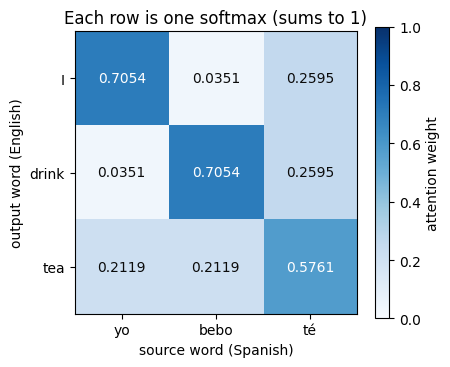

In [20]:
H = np.array([[1, 0], [0, 1], [1, 1.0]])               # encoder states: yo, bebo, te
s_drink = np.array([-1, 2.0])
e = H @ s_drink
assert e.tolist() == [-1, 2, 1]
check("sum of exponentials", np.exp(e).sum(), "10.4752")
alpha = softmax(e)
for name, a, hand in zip(["yo", "bebo", "te"], alpha, ["0.0351", "0.7054", "0.2595"]):
    check(f"alpha({name})", a, hand)
c = alpha @ H
check("context c[0]", c[0], "0.2946")
check("context c[1]", c[1], "0.9649")

S = np.array([[2, -1], [-1, 2], [1, 1.0]])             # decoder states for "I", "drink", "tea"
weights = np.array([softmax(row) for row in S @ H.T])  # one softmax per output word
print(weights)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(["yo", "bebo", "té"])
ax.set_yticks(range(3)); ax.set_yticklabels(["I", "drink", "tea"])
ax.set_xlabel("source word (Spanish)"); ax.set_ylabel("output word (English)")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{weights[i, j]:.4f}", ha="center", va="center",
                color="white" if weights[i, j] > 0.5 else "#0b0b0b", fontsize=10)
fig.colorbar(im, ax=ax, label="attention weight")
ax.set_title("Each row is one softmax (sums to 1)")
plt.tight_layout()
plt.show()

### Try it yourself

Compute the weights and the context vector for the output word "tea", with $\mathbf s_\text{tea} = (1, 1)$.

<details><summary>Answer</summary>

Scores: yo $= 1$, bebo $= 1$, té $= 2$. Exponentials $2.7183, 2.7183, 7.3891$, sum $12.8256$ → $\alpha = [0.2119, 0.2119, 0.5761]$.
$\mathbf c = (0.2119 + 0.5761,\ 0.2119 + 0.5761) = (0.7881, 0.7881)$ (computed from unrounded weights).

</details>

**Exam tip:** the weights always sum to 1, and $\mathbf c$ has the same size as one encoder state. The dot-product score needs $\mathbf s$ and $\mathbf h$ of the same size; otherwise use the "general" score $\mathbf s^\top W\mathbf h$ or additive attention.

## 20. Transformer numbers: positional encoding, scaled dot-product attention, causal mask, multi-head shapes

**What it is.** A Transformer has no recurrence, so it adds a **positional encoding** (PE) vector to each token embedding to tell the model where the token is. Self-attention computes $\text{Attention}(Q, K, V) = \text{softmax}\!\left(\dfrac{QK^\top}{\sqrt{d_k}}\right)V$. A decoder uses a **causal mask** so a token cannot look at later tokens. **Multi-head** attention splits $d_\text{model}$ into $h$ heads of size $d_k = d_\text{model}/h$.

**Everyday analogy.** Positional encoding is the seat number printed on each theatre ticket. The causal mask is like reading a mystery novel with the later pages glued shut. (The deep-learning notebooks build these blocks in code; here we only do the arithmetic.)

**How it works.**
$$PE(pos, 2i) = \sin\!\left(\frac{pos}{10000^{2i/d}}\right),\qquad PE(pos, 2i+1) = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

### Problem

(a) PE vectors for positions 0, 1, 2 with $d_\text{model} = 4$ (angles in radians).
(b) Two tokens, $d_k = 2$: $Q = \begin{bmatrix}1 & 0\\ 1 & 1\end{bmatrix}$, $K = \begin{bmatrix}1 & 0\\ 0 & 2\end{bmatrix}$, $V = \begin{bmatrix}1 & 2\\ 3 & 0\end{bmatrix}$ (one row per token). Compute the scaled scores, the attention weights and the outputs.
(c) Already-scaled scores for 3 tokens: $S = \begin{bmatrix}2 & 1 & 0\\ 1 & 3 & 1\\ 0 & 1 & 2\end{bmatrix}$. Apply the causal mask ($-\infty$ above the diagonal) and the row-wise softmax.
(d) $d_\text{model} = 768$, $h = 12$ heads, sequence length $n = 10$, batch size 1: find $d_k$, the shapes of one head's $Q$, one head's score matrix, all heads' scores, the concatenated output, and the number of parameters of the attention layer ($W_Q, W_K, W_V, W_O$, each $768 \times 768$ with a bias).

### Solution by hand

**Part (a): positional encoding.** With $d = 4$: $i = 0$ uses $10000^{0} = 1$; $i = 1$ uses $10000^{2/4} = 100$. So $PE(pos) = [\sin pos,\ \cos pos,\ \sin(pos/100),\ \cos(pos/100)]$.

| pos | $\sin(pos)$ | $\cos(pos)$ | $\sin(pos/100)$ | $\cos(pos/100)$ |
|---|---|---|---|---|
| 0 | 0.0000 | 1.0000 | 0.0000 | 1.0000 |
| 1 | 0.8415 | 0.5403 | 0.0100 | 1.0000 (0.99995) |
| 2 | 0.9093 | −0.4161 | 0.0200 | 0.9998 |

Low dimensions change quickly with position, high dimensions change slowly, like the second and hour hands of a clock.

**Part (b): scaled dot-product attention**
- $QK^\top$: row 1 $= [q_1\cdot k_1,\ q_1\cdot k_2] = [1, 0]$; row 2 $= [q_2\cdot k_1,\ q_2\cdot k_2] = [1, 2]$
- divide by $\sqrt{d_k} = \sqrt2 = 1.4142$: $\begin{bmatrix}0.7071 & 0\\ 0.7071 & 1.4142\end{bmatrix}$
- row 1 softmax: $e^{0.7071} = 2.0281$, $e^{0} = 1$, sum 3.0281 → $[0.6698, 0.3302]$
- row 2 softmax: $e^{0.7071} = 2.0281$, $e^{1.4142} = 4.1133$, sum 6.1414 → $[0.3302, 0.6698]$
- output row 1 $= 0.6698 \times (1, 2) + 0.3302 \times (3, 0) = (0.6698 + 0.9907,\ 1.3395) = $ **(1.6605, 1.3395)**
- output row 2 $= 0.3302 \times (1, 2) + 0.6698 \times (3, 0) = (0.3302 + 2.0093,\ 0.6605) = $ **(2.3395, 0.6605)**

**Part (c): causal mask.** Masked scores: row 1 $= [2, -\infty, -\infty]$, row 2 $= [1, 3, -\infty]$, row 3 $= [0, 1, 2]$. Because $e^{-\infty} = 0$, masked positions get weight exactly 0.
- row 1: $[1, 0, 0]$ (the first token can only look at itself)
- row 2: $e^{1} = 2.7183$, $e^{3} = 20.0855$, sum 22.8038 → $[0.1192, 0.8808, 0]$
- row 3: $e^{0} = 1$, $e^{1} = 2.7183$, $e^{2} = 7.3891$, sum 11.1073 → $[0.0900, 0.2447, 0.6652]$

Without the mask, row 1 would be $[0.6652, 0.2447, 0.0900]$: token 1 would "peek" at the future.

**Part (d): multi-head shapes**
- $d_k = 768 / 12 = $ **64**
- one head: $Q$ is (10, 64); scores $QK^\top$ are (10, 10); all heads together: (12, 10, 10)
- each head outputs (10, 64); concatenating 12 heads gives (10, $12 \times 64 = 768$); $W_O$ maps it back to (10, 768)
- parameters: $4 \times 768 \times 768 + 4 \times 768 = 2{,}359{,}296 + 3{,}072 = $ **2,362,368**

In [21]:
def positional_encoding(pos, d=4):
    pe = np.zeros(d)
    for i in range(d // 2):
        angle = pos / 10000 ** (2 * i / d)
        pe[2 * i], pe[2 * i + 1] = math.sin(angle), math.cos(angle)
    return pe

hand_pe = {0: ["0.0000", "1.0000", "0.0000", "1.0000"], 1: ["0.8415", "0.5403", "0.0100", "1.0000"],
           2: ["0.9093", "-0.4161", "0.0200", "0.9998"]}
for pos, row in hand_pe.items():
    pe = positional_encoding(pos)
    for k in range(4):
        check(f"PE({pos}, {k})", pe[k], row[k])

Q = np.array([[1, 0], [1, 1.0]]); K = np.array([[1, 0], [0, 2.0]]); Vm = np.array([[1, 2], [3, 0.0]])
scaled = Q @ K.T / math.sqrt(2)
W = np.array([softmax(row) for row in scaled])
out = W @ Vm
check("scaled score [0,0]", scaled[0, 0], "0.7071")
check("scaled score [1,1]", scaled[1, 1], "1.4142")
check("weight [0,0]", W[0, 0], "0.6698"); check("weight [0,1]", W[0, 1], "0.3302")
check("weight [1,0]", W[1, 0], "0.3302"); check("weight [1,1]", W[1, 1], "0.6698")
for (i, j), hand in {(0, 0): "1.6605", (0, 1): "1.3395", (1, 0): "2.3395", (1, 1): "0.6605"}.items():
    check(f"output [{i},{j}]", out[i, j], hand)

S = np.array([[2, 1, 0], [1, 3, 1], [0, 1, 2.0]])
masked = np.where(np.triu(np.ones((3, 3), dtype=bool), k=1), -np.inf, S)   # -inf above the diagonal
Wc = np.array([softmax(row) for row in masked])
print(Wc)
hand_c = [["1.0000", "0.0000", "0.0000"], ["0.1192", "0.8808", "0.0000"], ["0.0900", "0.2447", "0.6652"]]
for i in range(3):
    for j in range(3):
        check(f"causal weight [{i},{j}]", Wc[i, j], hand_c[i][j])

d_model, heads, n = 768, 12, 10
d_k = d_model // heads
check("d_k", d_k, 64)
x = np.zeros((n, d_model))
q_heads = (x @ np.zeros((d_model, d_model))).reshape(n, heads, d_k).transpose(1, 0, 2)
assert q_heads.shape == (12, 10, 64) and (q_heads @ q_heads.transpose(0, 2, 1)).shape == (12, 10, 10)
check("attention-layer parameters", 4 * d_model * d_model + 4 * d_model, 2_362_368)
try:
    import torch.nn as nn
    mha = nn.MultiheadAttention(embed_dim=768, num_heads=12)
    check("torch MultiheadAttention parameters", sum(p.numel() for p in mha.parameters()), 2_362_368)
except ImportError:
    print("skipped: needs torch")

OK  PE(0, 0)                                     code = 0.000000     hand = 0.0000
OK  PE(0, 1)                                     code = 1.000000     hand = 1.0000
OK  PE(0, 2)                                     code = 0.000000     hand = 0.0000
OK  PE(0, 3)                                     code = 1.000000     hand = 1.0000
OK  PE(1, 0)                                     code = 0.841471     hand = 0.8415
OK  PE(1, 1)                                     code = 0.540302     hand = 0.5403
OK  PE(1, 2)                                     code = 0.010000     hand = 0.0100
OK  PE(1, 3)                                     code = 0.999950     hand = 1.0000
OK  PE(2, 0)                                     code = 0.909297     hand = 0.9093
OK  PE(2, 1)                                     code = -0.416147    hand = -0.4161
OK  PE(2, 2)                                     code = 0.019999     hand = 0.0200
OK  PE(2, 3)                                     code = 0.999800     hand = 0.9998
OK 

OK  attention-layer parameters                   code = 2362368.000000 hand = 2362368
skipped: needs torch


### Try it yourself

(a) Positional encoding of position 3 with $d_\text{model} = 4$. (b) $d_k$ and the attention-layer parameter count for $d_\text{model} = 512$ and 8 heads.

<details><summary>Answer</summary>

(a) $[\sin 3, \cos 3, \sin 0.03, \cos 0.03] = [0.1411, -0.9900, 0.0300, 0.9996]$.
(b) $d_k = 512 / 8 = 64$; parameters $= 4 \times 512^2 + 4 \times 512 = 1{,}048{,}576 + 2{,}048 = 1{,}050{,}624$.

</details>

**Exam tip:** divide by $\sqrt{d_k}$ (the size of one head), not $\sqrt{d_\text{model}}$. Apply the mask **before** the softmax (as $-\infty$); zeroing weights after the softmax leaves rows that no longer sum to 1.

## 21. BERT masked language modelling: the 15% and 80/10/10 rule

**What it is.** BERT is pre-trained by hiding some input tokens and predicting them from both sides. **15%** of the tokens are selected; of those, **80%** are replaced by `[MASK]`, **10%** by a random token and **10%** are left unchanged. The loss is computed **only at the selected positions**.

**Everyday analogy.** A fill-in-the-blanks worksheet where a few "blanks" are traps (a wrong word, or the right word left in place), so you cannot just hunt for the blanks: you must check every word.

**How it works.** Expected counts $= n \times 0.15 \times (0.8, 0.1, 0.1)$. MLM loss $=$ average of $-\ln p(\text{true token})$ over the selected positions.

### Problem

(a) For a 20-token sentence, find the expected number of selected tokens, of `[MASK]` tokens, of random replacements and of unchanged-but-predicted tokens, and the fraction of all tokens that become `[MASK]`.
(b) The 3 selected positions get model probabilities 0.6, 0.3 and 0.9 for their true tokens. Compute the MLM loss.

### Solution by hand

**Step 1: counts**
- selected: $0.15 \times 20 = $ **3**
- replaced by `[MASK]`: $0.8 \times 3 = $ **2.4** on average; random token: $0.1 \times 3 = $ **0.3**; unchanged: **0.3**
- (in one real sentence the counts are whole numbers, for example 2/1/0 or 3/0/0; the values above are averages)
- fraction of **all** tokens that become `[MASK]`: $0.15 \times 0.8 = 0.12 = $ **12%**; random: $0.15 \times 0.1 = 1.5\%$; unchanged but still predicted: 1.5%

**Step 2: loss on the selected positions only**
$L = \dfrac{-\ln 0.6 - \ln 0.3 - \ln 0.9}{3} = \dfrac{0.5108 + 1.2040 + 0.1054}{3} = \dfrac{1.8202}{3} = $ **0.6067**
The other 17 positions add nothing (in PyTorch their label is set to −100, which the loss ignores).

In [22]:
n_tokens = 20
selected = 0.15 * n_tokens
check("selected tokens", selected, 3)
check("expected [MASK]", 0.8 * selected, "2.4")
check("expected random", 0.1 * selected, "0.3")
check("expected unchanged", 0.1 * selected, "0.3")
check("fraction of all tokens -> [MASK]", 0.15 * 0.8, "0.12")

p_true = np.array([0.6, 0.3, 0.9])
check("sum of -ln p", -np.log(p_true).sum(), "1.8202")
check("MLM loss", -np.log(p_true).mean(), "0.6067")

# Simulation: apply the rule to 200,000 token positions and measure the fractions
rng = np.random.default_rng(0)
u_select, u_kind = rng.random(200_000), rng.random(200_000)
is_selected = u_select < 0.15
frac_mask = np.mean(is_selected & (u_kind < 0.8))
frac_random = np.mean(is_selected & (u_kind >= 0.8) & (u_kind < 0.9))
print(f"simulated: selected {is_selected.mean():.4f}, [MASK] {frac_mask:.4f}, random {frac_random:.4f}")
assert abs(frac_mask - 0.12) < 0.003 and abs(frac_random - 0.015) < 0.002

OK  selected tokens                              code = 3.000000     hand = 3
OK  expected [MASK]                              code = 2.400000     hand = 2.4
OK  expected random                              code = 0.300000     hand = 0.3
OK  expected unchanged                           code = 0.300000     hand = 0.3
OK  fraction of all tokens -> [MASK]             code = 0.120000     hand = 0.12
OK  sum of -ln p                                 code = 1.820159     hand = 1.8202
OK  MLM loss                                     code = 0.606720     hand = 0.6067
simulated: selected 0.1511, [MASK] 0.1207, random 0.0151


### Try it yourself

For a 40-token sentence: expected selected, `[MASK]`, random and unchanged counts? If the selected positions get true-token probabilities 0.5, 0.8, 0.2, 0.9, 0.7, 0.4, what is the MLM loss?

<details><summary>Answer</summary>

Selected $0.15 \times 40 = 6$; `[MASK]` $4.8$; random $0.6$; unchanged $0.6$.
Losses: 0.6931, 0.2231, 1.6094, 0.1054, 0.3567, 0.9163; sum 3.9041; MLM loss $= 3.9041 / 6 = 0.6507$.

</details>

**Exam tip:** the loss includes the random-token and unchanged positions too (they were selected); it is not only computed at the `[MASK]` tokens.

## 22. Byte-pair encoding (BPE) merges

**What it is.** BPE builds a **subword** vocabulary. Start from single characters and repeatedly merge the most frequent pair of neighbouring symbols into a new symbol.

**Everyday analogy.** Inventing shorthand: the letter pairs you write most often get their own quick symbol first.

**How it works.** Count every adjacent symbol pair, weighted by how often its word occurs; merge the top pair everywhere; repeat. To tokenize a new word, apply the learned merges in the same order.

### Problem

Word frequencies: sun 4, sunny 2, fun 3, funny 1. Every word ends with the end-of-word symbol `_`. Learn 3 merges. Then tokenize "funny" and "nun" with the learned merges. How big is the vocabulary after the merges?

### Solution by hand

**Step 1: start.** `s u n _` (4), `s u n n y _` (2), `f u n _` (3), `f u n n y _` (1). Initial symbols: s, u, n, y, f, `_` → 6.

**Step 2: pair counts** (each pair counted once per occurrence, times the word frequency):

| pair | from | count |
|---|---|---|
| `u n` | 4 + 2 + 3 + 1 | **10** |
| `n _` | 4 + 3 | 7 |
| `s u` | 4 + 2 | 6 |
| `f u` | 3 + 1 | 4 |
| `n n` | 2 + 1 | 3 |
| `n y` | 2 + 1 | 3 |
| `y _` | 2 + 1 | 3 |

**Merge 1:** `u` + `n` → `un`. Words: `s un _` (4), `s un n y _` (2), `f un _` (3), `f un n y _` (1).

**Step 3: recount.** `un _` 4 + 3 = **7**; `s un` 6; `f un` 4; `un n` 3; `n y` 3; `y _` 3.
**Merge 2:** `un` + `_` → `un_`. Words: `s un_` (4), `s un n y _` (2), `f un_` (3), `f un n y _` (1).

**Step 4: recount.** `s un_` **4**; `f un_` 3; `un n` 3; `n y` 3; `y _` 3; `s un` 2; `f un` 1.
**Merge 3:** `s` + `un_` → `sun_`. Words: `sun_` (4), `s un n y _` (2), `f un_` (3), `f un n y _` (1).

**Step 5: results.** Learned merges in order: (u, n), (un, `_`), (s, `un_`). Vocabulary size $= 6 + 3 = $ **9**.
- "funny" = `f u n n y _` → merge 1 → `f un n y _`; merge 2 does not apply (`un` is followed by `n`); merge 3 does not apply → **[f, un, n, y, _]**
- "nun" = `n u n _` → merge 1 → `n un _` → merge 2 → **[n, un_]**

In [23]:
def learn_bpe(word_freqs, num_merges):
    words = {tuple(w) + ("_",): c for w, c in word_freqs.items()}
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for symbols, c in words.items():
            for a, b in zip(symbols, symbols[1:]):
                pairs[(a, b)] += c
        (best, best_count), (_second, second_count) = pairs.most_common(2)
        assert best_count > second_count, "tie: the problem would need a tie-breaking rule"
        print("pair counts:", dict(pairs.most_common()), "-> merge", best)
        merges.append(best)
        words = {apply_merge(s, best): c for s, c in words.items()}
    return merges, words

def apply_merge(symbols, pair):
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2
        else:
            out.append(symbols[i]); i += 1
    return tuple(out)

def bpe_tokenize(word, merges):
    symbols = tuple(word) + ("_",)
    for pair in merges:                                  # apply merges in the learned order
        symbols = apply_merge(symbols, pair)
    return list(symbols)

merges, final_words = learn_bpe({"sun": 4, "sunny": 2, "fun": 3, "funny": 1}, 3)
assert merges == [("u", "n"), ("un", "_"), ("s", "un_")]
check("vocabulary size after 3 merges", len(set("sunfy_")) + len(merges), 9)
assert bpe_tokenize("funny", merges) == ["f", "un", "n", "y", "_"]
assert bpe_tokenize("nun", merges) == ["n", "un_"]
print("funny ->", bpe_tokenize("funny", merges), "| nun ->", bpe_tokenize("nun", merges))

pair counts: {('u', 'n'): 10, ('n', '_'): 7, ('s', 'u'): 6, ('f', 'u'): 4, ('n', 'n'): 3, ('n', 'y'): 3, ('y', '_'): 3} -> merge ('u', 'n')
pair counts: {('un', '_'): 7, ('s', 'un'): 6, ('f', 'un'): 4, ('un', 'n'): 3, ('n', 'y'): 3, ('y', '_'): 3} -> merge ('un', '_')
pair counts: {('s', 'un_'): 4, ('un', 'n'): 3, ('n', 'y'): 3, ('y', '_'): 3, ('f', 'un_'): 3, ('s', 'un'): 2, ('f', 'un'): 1} -> merge ('s', 'un_')
OK  vocabulary size after 3 merges               code = 9.000000     hand = 9
funny -> ['f', 'un', 'n', 'y', '_'] | nun -> ['n', 'un_']


### Try it yourself

Word frequencies: cat 5, cats 2, act 3 (each with `_`). Find the first two merges and the vocabulary size after them.

<details><summary>Answer</summary>

Pair counts: `t _` 5 + 3 = 8, `c a` 5 + 2 = 7, `a t` 7, `a c` 3, `c t` 3, `t s` 2, `s _` 2 → **merge 1: `t` + `_` → `t_`**.
Words: `c a t_` (5), `c a t s _` (2), `a c t_` (3). New counts: `c a` 7, `a t_` 5, `a c` 3, `c t_` 3, `a t` 2, `t s` 2, `s _` 2 → **merge 2: `c` + `a` → `ca`**.
Vocabulary: 5 initial symbols (a, c, t, s, `_`) + 2 merges = 7.

</details>

**Exam tip:** state the tie-breaking rule if two pairs have the same count, and apply merges in the learned order when you tokenize a new word. GPT-style tokenizers run BPE on bytes; BERT's WordPiece picks merges by a likelihood score instead of the raw count.

## 23. NER evaluation: token-level vs entity-level scores

**What it is.** Named-entity recognition (NER) labels tokens with **BIO** tags: B- (beginning of an entity), I- (inside), O (outside). **Token-level** scores give credit per token. **Entity-level** scores (the CoNLL / seqeval standard) count an entity as correct only if its whole span **and** its type are exactly right.

**Everyday analogy.** Marking a highlighting exercise: token-level gives a point for every correctly highlighted word; entity-level gives a point only for a phrase highlighted completely, in the right colour.

**How it works.** Write each entity as (type, start, end). $TP$ = entities in both lists; precision $= TP / \#\text{predicted}$; recall $= TP / \#\text{gold}$; $F_1 = \dfrac{2PR}{P+R} = \dfrac{2TP}{\#\text{predicted} + \#\text{gold}}$.

### Problem

| token | Maria | Lopez | flew | from | New | York | to | Paris |
|---|---|---|---|---|---|---|---|---|
| gold | B-PER | I-PER | O | O | B-LOC | I-LOC | O | B-LOC |
| predicted | B-PER | I-PER | O | O | B-LOC | B-LOC | O | B-ORG |

Compute (a) token accuracy; (b) token-level micro precision, recall and F1 over the non-O tags (a token counts as correct only if its full tag matches); (c) entity-level precision, recall and F1.

### Solution by hand

**Step 1: token accuracy.** Correct tags: Maria, Lopez, flew, from, New, to → 6 of 8 = **0.7500** (York and Paris are wrong).

**Step 2: token level (non-O tags).**
- predicted non-O tokens: Maria, Lopez, New, York, Paris = 5; correct among them: Maria, Lopez, New = 3 → $P = 3/5 = 0.6000$
- gold non-O tokens: Maria, Lopez, New, York, Paris = 5; correctly tagged: 3 → $R = 3/5 = 0.6000$
- $F_1 = $ **0.6000**

**Step 3: entity level.**
- gold entities: PER "Maria Lopez" (tokens 0-1), LOC "New York" (4-5), LOC "Paris" (7) → 3
- predicted entities: PER "Maria Lopez" (0-1), LOC "New" (4), LOC "York" (5), ORG "Paris" (7) → 4
- exact matches: only PER "Maria Lopez" → $TP = 1$
- $P = 1/4 = 0.2500$; $R = 1/3 = 0.3333$; $F_1 = \dfrac{2 \times 0.25 \times 0.3333}{0.25 + 0.3333} = \dfrac{2 \times 1}{4 + 3} = $ **0.2857**

Entity-level F1 (0.2857) is far harsher than token-level F1 (0.6000): splitting "New York" into two entities costs one missed entity **and** two false positives, and the wrong type for "Paris" costs one of each.

In [24]:
gold = "B-PER I-PER O O B-LOC I-LOC O B-LOC".split()
pred = "B-PER I-PER O O B-LOC B-LOC O B-ORG".split()

def entities(tags):
    # (type, start, end) spans from BIO tags; an I- tag that does not continue an entity starts a new one
    spans, current = [], None
    for i, tag in enumerate(tags):
        if tag.startswith("B-") or (tag.startswith("I-") and (current is None or current[0] != tag[2:])):
            if current: spans.append(tuple(current))
            current = [tag[2:], i, i]
        elif tag.startswith("I-"):
            current[2] = i
        else:
            if current: spans.append(tuple(current))
            current = None
    if current: spans.append(tuple(current))
    return set(spans)

check("token accuracy", np.mean([g == p for g, p in zip(gold, pred)]), "0.7500")
from sklearn.metrics import precision_score, recall_score, f1_score
labels = sorted({t for t in gold + pred if t != "O"})            # every non-O tag that occurs
check("token-level precision", precision_score(gold, pred, labels=labels, average="micro"), "0.6000")
check("token-level recall", recall_score(gold, pred, labels=labels, average="micro"), "0.6000")
check("token-level F1", f1_score(gold, pred, labels=labels, average="micro"), "0.6000")

G, Pset = entities(gold), entities(pred)
print("gold entities:", sorted(G)); print("predicted entities:", sorted(Pset))
tp = len(G & Pset)
check("entity TP", tp, 1)
P_ent, R_ent = tp / len(Pset), tp / len(G)
check("entity precision", P_ent, "0.2500")
check("entity recall", R_ent, "0.3333")
check("entity F1", 2 * P_ent * R_ent / (P_ent + R_ent), "0.2857")
try:
    from seqeval.metrics import f1_score as seqeval_f1
    check("seqeval entity F1", seqeval_f1([gold], [pred]), "0.2857")
except ImportError:
    print("skipped: needs seqeval")

OK  token accuracy                               code = 0.750000     hand = 0.7500
OK  token-level precision                        code = 0.600000     hand = 0.6000
OK  token-level recall                           code = 0.600000     hand = 0.6000
OK  token-level F1                               code = 0.600000     hand = 0.6000
gold entities: [('LOC', 4, 5), ('LOC', 7, 7), ('PER', 0, 1)]
predicted entities: [('LOC', 4, 4), ('LOC', 5, 5), ('ORG', 7, 7), ('PER', 0, 1)]
OK  entity TP                                    code = 1.000000     hand = 1
OK  entity precision                             code = 0.250000     hand = 0.2500
OK  entity recall                                code = 0.333333     hand = 0.3333
OK  entity F1                                    code = 0.285714     hand = 0.2857
skipped: needs seqeval


### Try it yourself

Score a second prediction: B-PER O O O B-LOC I-LOC O B-LOC ("Lopez" is missed, everything else is right).

<details><summary>Answer</summary>

- Token accuracy: 7/8 = 0.8750.
- Token level: predicted non-O = Maria, New, York, Paris = 4, all correct → $P = 4/4 = 1.0000$; gold non-O = 5 → $R = 4/5 = 0.8000$; $F_1 = 0.8889$.
- Entity level: predicted = PER "Maria" (wrong span), LOC "New York", LOC "Paris" → $TP = 2$; $P = 2/3 = 0.6667$, $R = 2/3 = 0.6667$, $F_1 = 0.6667$.

</details>

**Exam tip:** always say which convention you use. Some token-level reports ignore the B-/I- prefix (then York's B-LOC vs I-LOC would count as correct); entity-level scoring with exact span and type (seqeval) is the standard for NER benchmarks.

## Recap cheat sheet

| # | Topic | Formula / rule |
|---|---|---|
| 1 | Bag of words | tokens = all occurrences; types $\lvert V\rvert$ = distinct words; vector = count of each vocabulary word |
| 2 | TF-IDF | textbook $\text{idf} = \ln\frac{N}{\text{df}}$; scikit-learn $\ln\frac{1+N}{1+\text{df}} + 1$ then L2-normalize; weight = TF × IDF |
| 2, 5 | Cosine similarity | $\cos(\mathbf a,\mathbf b) = \frac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\lVert\mathbf b\rVert}$; Euclidean $\sqrt{\sum (a_i - b_i)^2}$ |
| 3 | Frequency features + LR | $\mathbf x = [1, \sum\text{freq}_\text{pos}, \sum\text{freq}_\text{neg}]$, $p = \sigma(\boldsymbol\theta\cdot\mathbf x)$, loss $-[y\ln p + (1-y)\ln(1-p)]$ |
| 4 | Naive Bayes | $P(w\mid c) = \frac{\text{freq}(w,c)+1}{N_c + \lvert V\rvert}$, $\lambda(w) = \ln\frac{P(w\mid\text{pos})}{P(w\mid\text{neg})}$, score = $\ln\frac{D_\text{pos}}{D_\text{neg}} + \sum\lambda$ |
| 5 | Analogy, neutralize | $\mathbf r = \text{king} - \text{man} + \text{woman}$ (exclude inputs); $\mathbf e - \frac{\mathbf e\cdot\mathbf g}{\lVert\mathbf g\rVert^2}\mathbf g$ |
| 6 | Word translation, LSH | loss $\lVert XR - Y\rVert_F^2$, gradient $\frac{2}{m}X^\top(XR - Y)$; bucket $= \sum_i 2^{i-1}[\mathbf p_i\cdot\mathbf v \ge 0]$ |
| 7 | Edit distance | $D[i,j] = \min(D[i-1,j]+1,\ D[i,j-1]+1,\ D[i-1,j-1] + \{0, \text{sub}\})$ |
| 8 | Autocorrect | one edit: $n$ deletes, $n-1$ swaps, $25n$ replaces, $26(n+1)$ inserts; pick $\max P(w) = \text{count}/N$ |
| 9 | N-grams | MLE $\frac{C(\text{prev}\ w)}{C(\text{prev})}$; add-$k$ $\frac{C + k}{C(\text{prev}) + k\lvert V\rvert}$; interpolation $\lambda_2 P_\text{bi} + \lambda_1 P_\text{uni}$; $PP = P^{-1/M}$ |
| 10 | Viterbi | $v_t(j) = \max_i v_{t-1}(i)A(i\to j)\,B(j, w_t)$, $v_1(j) = \pi(j)B(j, w_1)$, follow backpointers |
| 11 | word2vec | pairs $= 2mT - m(m+1)$; $P(o\mid c) = \text{softmax}(\mathbf u\cdot\mathbf v_c)_o$; $L_\text{neg} = -\ln\sigma(\mathbf u_o\cdot\mathbf v_c) - \sum_k\ln\sigma(-\mathbf u_k\cdot\mathbf v_c)$; CBOW averages context vectors |
| 12 | GloVe | $f(x) = (x/100)^{0.75}$ if $x < 100$ else 1; term $f(X_{ij})(\mathbf w_i\cdot\tilde{\mathbf w}_j + b_i + \tilde b_j - \ln X_{ij})^2$ |
| 13 | RNN family | block $= h(h + x) + h$; RNN ×1, GRU ×3, LSTM ×4 (PyTorch: $+h$ per block) |
| 14 | LM loss | average $-\ln p_t$; $PP = e^{\text{avg loss}} = 2^{\text{avg bits}}$; temperature $p_i \propto e^{z_i/T}$ |
| 15 | Triplet loss | $\max(0, \cos(A, N) - \cos(A, P) + \alpha)$; hard negative = most similar negative |
| 16 | Beam search | keep top $B$ by $\sum\ln P$; final choice by $\frac{1}{T^\alpha}\sum\ln P$ |
| 17 | BLEU | clipped $p_n$; $\text{BP} = e^{1 - r/c}$ if $c \le r$; $\text{BLEU} = \text{BP}\cdot\exp(\sum\frac1N\ln p_n)$ |
| 17 | ROUGE | $R = \frac{\text{overlap}}{\text{ref}}$, $P = \frac{\text{overlap}}{\text{cand}}$, $F_1 = \frac{2\,\text{overlap}}{\text{ref} + \text{cand}}$; ROUGE-L uses the LCS |
| 18 | WER | $\frac{S + D + I}{N_\text{ref}}$ (can exceed 1) |
| 19 | Attention | $e_i = \mathbf s\cdot\mathbf h_i$, $\boldsymbol\alpha = \text{softmax}(\mathbf e)$, $\mathbf c = \sum\alpha_i\mathbf h_i$ |
| 20 | Transformer | $PE(pos, 2i) = \sin(pos/10000^{2i/d})$, $PE(pos, 2i+1) = \cos(\cdot)$; $\text{softmax}(QK^\top/\sqrt{d_k})V$; mask $-\infty$ before softmax; $d_k = d_\text{model}/h$; MHA params $4d^2 + 4d$ |
| 21 | BERT MLM | select 15%: 80% `[MASK]`, 10% random, 10% unchanged (12% / 1.5% / 1.5% of all tokens); loss on selected positions only |
| 22 | BPE | merge the most frequent adjacent pair (weighted by word counts); vocabulary grows by 1 per merge |
| 23 | NER scores | entity-level: exact (type, start, end) match; $F_1 = \frac{2TP}{\#\text{pred} + \#\text{gold}}$ |

## Related notebooks in this repo

- [Start here: turning text into numbers](00_start_here_text_to_numbers.ipynb): tokenization, bag of words, TF-IDF, cosine similarity and embeddings in code
- [Text preprocessing](01_text_preprocessing.ipynb): cleaning, tokenization, stemming and lemmatization
- [Word embeddings](02_word_embeddings.ipynb): word2vec and GloVe trained and explored in code
- [Text classification](03_text_classification.ipynb): Naive Bayes and TF-IDF classifiers on real data
- [Named entity recognition](04_named_entity_recognition.ipynb): BIO tagging and NER models
- [Language models and generation](05_language_models_and_generation.ipynb): n-gram models, decoding strategies, BLEU and ROUGE
- [Speech and audio](08_speech_and_audio.ipynb): speech recognition, where WER is the standard metric
- [Advanced sentence embeddings](09_sentence_embeddings_advanced.ipynb): Siamese bi-encoders and sentence similarity
- [Advanced NLP tasks](10_advanced_nlp_tasks.ipynb): part-of-speech tagging, parsing, paraphrase detection
- [LLM and generative-AI numericals solved by hand](../08_LLM/00b_llm_and_genai_numericals_solved_by_hand.ipynb): the next step in the same style (tokens, cost, memory, compute, sampling, RAG)
- [Deep-learning numericals, part 2](../05_Deep_Learning/00c_dl_numericals_part2_cnn_rnn_attention.ipynb): more RNN, LSTM and attention arithmetic by hand
- [How LLMs work](../08_LLM/00_start_here_how_llms_work.ipynb): next-token prediction, temperature and sampling for large models
- [Inside a Transformer: maths and code](../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb): tokens, positional information, self-attention and the loss, step by step
- [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb): BLEU, ROUGE and modern evaluation methods
- [Tokens, cost, batching and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb): how BPE tokens turn into API cost
- [RNNs, LSTMs, GRUs](../05_Deep_Learning/04_rnn_lstm_gru.ipynb) and [sequence models hands-on](../05_Deep_Learning/19_sequence_models_hands_on.ipynb): RNN cells, beam search and attention in PyTorch
- [Transformer architecture](../05_Deep_Learning/05_transformers_architecture.ipynb): positional encoding, masks and multi-head attention in code

## Additional Learning Resources

- Dan Jurafsky and James H. Martin, *Speech and Language Processing* (3rd edition draft, free online): [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/). Chapters on n-grams, Naive Bayes, vector semantics, HMM/POS tagging, edit distance, RNNs and Transformers.
- Stanford CS224N, *Natural Language Processing with Deep Learning*: [web.stanford.edu/class/cs224n](https://web.stanford.edu/class/cs224n/)
- DeepLearning.AI, *Natural Language Processing Specialization*: [deeplearning.ai/courses/natural-language-processing-specialization](https://www.deeplearning.ai/courses/natural-language-processing-specialization/)
- DeepLearning.AI, *Deep Learning Specialization* (Course 5: Sequence Models): [deeplearning.ai/courses/deep-learning-specialization](https://www.deeplearning.ai/courses/deep-learning-specialization/)
- Original papers, if you want the source of a formula: Papineni et al. 2002 (BLEU), Lin 2004 (ROUGE), Mikolov et al. 2013 (word2vec and negative sampling), Pennington et al. 2014 (GloVe), Bahdanau et al. 2015 (attention), Sennrich et al. 2016 (BPE for NMT), Vaswani et al. 2017 (Transformer), Devlin et al. 2019 (BERT), Bolukbasi et al. 2016 (debiasing word embeddings).